# Тема 06. Деревья решений и ансамбли на датасете Titanic

Инженерное исследование деревьев решений (`CART`), беггинга (`Random Forest`) и градиентного бустинга (`XGBoost`, `LightGBM`, `CatBoost`) на классическом табличном датасете **Kaggle Titanic** (`891` пассажир, `12` исходных столбцов).

### План эксперимента
1. **Подготовка эксперимента и защита от утечки данных (`Data Leakage`)**:
   - Анализ баланса целевой переменной `Survived`, структуры пропусков и выбор метрик (`F1` как основная пороговая метрика класса `1`, `ROC-AUC` как ранжирующая метрика, `Accuracy` как справочная).
   - Построчное конструирование признаков без подглядывания в статистики выборки (`FamilySize`, `IsAlone`, `Title`).
   - Отделение отложенной тестовой выборки `X_test` (`20%`, стратифицированно, `n = 179`) **до любых обучений и подбора гиперпараметров**.
   - Фиксация единого разбиения `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` и сборка `ColumnTransformer` + `Pipeline` для импутации и кодирования строго внутри фолдов.
   - Оценка тривиального `DummyClassifier` и линейного бейзлайна `LogisticRegression`.
2. **Дерево решений (`DecisionTreeClassifier`)**:
   - Ручная реализация критерия Джини (`Gini`), энтропии Шеннона (`Entropy`) и прироста информации (`Information Gain`) на чистом `NumPy` с проверкой `assert np.isclose(...)` против `tree_.impurity` из `scikit-learn`.
   - Демонстрация переобучения дерева без ограничений (`depth = 18`, `leaves = 164`, `Train F1 = 0.9786` при `CV F1 = 0.7209`).
   - Построение и визуализация компактного интерпретируемого дерева (`max_depth = 3`, `min_samples_leaf = 10`) с разбором конкретных продукционных правил `if-then`.
   - Исследование кривых валидации по `max_depth` (`1..15`) и `min_samples_leaf` (`1..50`) и тепловой карты `(max_depth x min_samples_leaf)`.
3. **Ансамбли: Bagging и Gradient Boosting**:
   - Честное сравнение `LogisticRegression`, `DecisionTree (default)`, `DecisionTree (depth=3, leaf=10)`, `RandomForest`, `XGBoost`, `LightGBM` и `CatBoost` на одних и тех же 5 фолдах (`mean +- std`).
   - Анализ распределения метрик по отдельным фолдам и демонстрация того, почему лидер одного фолда не обязан быть лучшей моделью в среднем.
4. **Подбор гиперпараметров (`GridSearchCV` и `RandomizedSearchCV`)**:
   - Систематический поиск гиперпараметров для `RandomForestClassifier`, `CatBoostClassifier` (`GridSearchCV`) и `LGBMClassifier` (`RandomizedSearchCV`).
   - Анализ топ-10 конфигураций из `cv_results_`, визуализация поверхностей качества и сокращения разрыва `Train - CV`.
5. **Финальная проверка на отложенном `X_test` и важность признаков**:
   - Однократная оценка выбранной по `CV` лучшей модели (`CatBoost (tuned)`) и эталонных бейзлайнов на `X_test` (`n = 179`).
   - Сравнение встроенной важности (`feature_importances_`) и перестановочной важности (`permutation_importance`), объяснение смещения `Gini Importance` в сторону непрерывных признаков высокой кардинальности (`Fare`, `Age`).
   - Итоговые инженерные выводы.


In [1]:
import os
import warnings
os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV,
    RandomizedSearchCV,
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve,
)
from sklearn.inspection import permutation_importance

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["font.size"] = 10
sns.set_theme(style="whitegrid")


## 1. Подготовка эксперимента

### 1.1. Загрузка данных, баланс классов и анализ пропусков
Загрузим таблицу `data/train.csv` и проверим размерность, типы столбцов, долю выживших и количество пропусков.


In [2]:
df_raw = pd.read_csv("data/train.csv")
print(f"Размерность исходного датасета: {df_raw.shape[0]} строк x {df_raw.shape[1]} столбцов")

# Баланс целевой переменной Survived
class_counts = df_raw["Survived"].value_counts().sort_index()
class_ratios = df_raw["Survived"].value_counts(normalize=True).sort_index() * 100
balance_df = pd.DataFrame({
    "Класс": ["0 (Погиб)", "1 (Выжил)"],
    "Количество": class_counts.values,
    "Доля, %": np.round(class_ratios.values, 2),
})
print("\nБаланс классов целевой переменной Survived:")
display(balance_df)

# Анализ пропусков
missing_counts = df_raw.isnull().sum()
missing_df = pd.DataFrame({
    "Признак": missing_counts.index,
    "Тип": df_raw.dtypes.values,
    "Пропусков": missing_counts.values,
    "Доля пропусков, %": np.round(missing_counts.values / len(df_raw) * 100, 2),
    "Уникальных значений": [df_raw[c].nunique(dropna=True) for c in df_raw.columns],
})
print("\nСтруктура признаков и пропусков:")
display(missing_df)


Размерность исходного датасета: 891 строк x 12 столбцов

Баланс классов целевой переменной Survived:


,Класс,Количество,"Доля, %"
0,0 (Погиб),549,61.62
1,1 (Выжил),342,38.38



Структура признаков и пропусков:


,Признак,Тип,Пропусков,"Доля пропусков, %",Уникальных значений
0,PassengerId,int64,0,0.00,891
1,Survived,int64,0,0.00,2
2,Pclass,int64,0,0.00,3
3,Name,str,0,0.00,891
4,Sex,str,0,0.00,2
5,Age,float64,177,19.87,88
6,SibSp,int64,0,0.00,7
7,Parch,int64,0,0.00,7
8,Ticket,str,0,0.00,681
9,Fare,float64,0,0.00,248


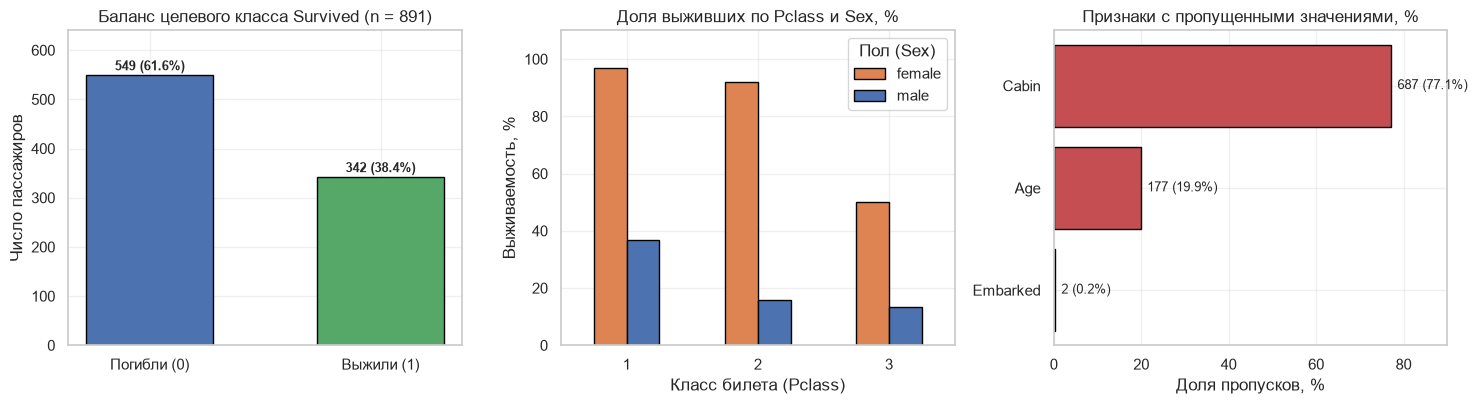

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# 1. Баланс классов
bars = axes[0].bar(
    ["Погибли (0)", "Выжили (1)"],
    class_counts.values,
    color=["#4C72B0", "#55A868"],
    edgecolor="black",
    width=0.55,
)
axes[0].set_title("Баланс целевого класса Survived (n = 891)")
axes[0].set_ylabel("Число пассажиров")
for bar, pct in zip(bars, class_ratios.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 10,
        f"{int(bar.get_height())} ({pct:.1f}%)",
        ha="center",
        fontsize=9.5,
        fontweight="bold",
    )
axes[0].set_ylim(0, 640)

# 2. Выживаемость по полу и классу каюты
surv_by_pclass_sex = (
    df_raw.groupby(["Pclass", "Sex"])["Survived"]
    .mean()
    .unstack() * 100
)
surv_by_pclass_sex.plot(
    kind="bar",
    ax=axes[1],
    color=["#DD8452", "#4C72B0"],
    edgecolor="black",
    rot=0,
)
axes[1].set_title("Доля выживших по Pclass и Sex, %")
axes[1].set_xlabel("Класс билета (Pclass)")
axes[1].set_ylabel("Выживаемость, %")
axes[1].set_ylim(0, 110)
axes[1].legend(title="Пол (Sex)")

# 3. Пропуски по признакам
miss_nonzero = missing_df[missing_df["Пропусков"] > 0].sort_values("Доля пропусков, %", ascending=True)
axes[2].barh(
    miss_nonzero["Признак"],
    miss_nonzero["Доля пропусков, %"],
    color="#C44E52",
    edgecolor="black",
)
axes[2].set_title("Признаки с пропущенными значениями, %")
axes[2].set_xlabel("Доля пропусков, %")
axes[2].set_xlim(0, 90)
for idx, (_, row) in enumerate(miss_nonzero.iterrows()):
    axes[2].text(
        row["Доля пропусков, %"] + 1.5,
        idx,
        f"{int(row['Пропусков'])} ({row['Доля пропусков, %']:.1f}%)",
        va="center",
        fontsize=9.5,
    )

plt.tight_layout()
plt.show()


### Обоснование выбора метрик качества
1. **Умеренный дисбаланс классов**: в выборке `549` погибших (`61.62%`) и `342` выживших (`38.38%`). Тривиальный классификатор, предсказывающий всем `0`, получает `Accuracy = 61.62%`, при этом не находя ни одного выжившего (`Recall = 0`, `F1 = 0`).
2. **Основная пороговая метрика — `F1-score` (по классу `1`)**: гармоническое среднее `Precision` и `Recall` штрафует как за ложные срабатывания (`FP`), так и за пропуски выживших (`FN`). На пороге `0.5` именно `F1` выбирается как целевая метрика `refit='f1'` при настройке гиперпараметров.
3. **Основная ранжирующая метрика — `ROC-AUC`**: оценивает способность ансамбля разделять распределения вероятностей $P(y=1 \mid x)$ независимо от выбранного порога отсечения.
4. **Вспомогательная метрика — `Accuracy`**: выводится справочно для сопоставимости с таблицами соревнования Kaggle Titanic.

### 1.2. Конструирование признаков без утечки данных и разбиение `Train / Test`
Все преобразования признаков ниже выполняются **строго построчно** (без вычисления медиан, частот или квантилей по всей таблице):
- `FamilySize = SibSp + Parch + 1` — полный размер семьи на борту;
- `IsAlone = 1`, если `FamilySize == 1`, иначе `0`;
- `Title` — обращение из поля `Name` (`Mr`, `Miss`, `Mrs`, `Master`; редкие дворянские и офицерские титулы объединены в фиксированную категорию `Rare`, что позволяет дереву отделить мальчиков `Master` от взрослых мужчин `Mr`);
- Удаляются технические идентификаторы и сырые текстовые поля с высокой долей пропусков или уникальных строк: `PassengerId`, `Name`, `Ticket`, `Cabin` (`77.1%` пропусков).

**Защита от утечки (`Data Leakage`)**:
- Отложенная выборка `X_test` (`20%`, `179` объектов) отделяется **до любых экспериментов** со стратификацией по `Survived`.
- Импутация пропусков (`Age` — медианой, `Embarked` — модой) и `OneHotEncoder` упакованы в `ColumnTransformer` внутри `Pipeline`, поэтому на кросс-валидации статистики считаются **только по обучающим фолдам**.


In [4]:
def extract_features(df: pd.DataFrame) -> pd.DataFrame:
    """Построчное выделение признаков без использования глобальных статистик выборки."""
    data = df.copy()
    data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
    data["IsAlone"] = (data["FamilySize"] == 1).astype(int)

    # Извлечение титула из имени пассажира
    titles = data["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
    titles = titles.replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
    standard_titles = ["Mr", "Miss", "Mrs", "Master"]
    data["Title"] = titles.where(titles.isin(standard_titles), "Rare")

    drop_cols = ["PassengerId", "Name", "Ticket", "Cabin", "Survived"]
    return data.drop(columns=[c for c in drop_cols if c in data.columns])


X_all = extract_features(df_raw)
y_all = df_raw["Survived"].values

# Отделяем отложенную тестовую выборку ДО начала всех экспериментов
X_train, X_test, y_train, y_test = train_test_split(
    X_all,
    y_all,
    test_size=0.20,
    stratify=y_all,
    random_state=RANDOM_STATE,
)

# Единый объект кросс-валидации для всех моделей и подбора гиперпараметров
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

num_cols = ["Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize", "IsAlone"]
cat_cols = ["Sex", "Embarked", "Title"]

# Препроцессор для деревянных моделей: без масштабирования чисел, чтобы пороги в узлах читались в натуральных единицах
preprocessor_tree = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), num_cols),
        (
            "cat",
            Pipeline([
                ("impute", SimpleImputer(strategy="most_frequent")),
                ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ]),
            cat_cols,
        ),
    ],
    verbose_feature_names_out=False,
)

# Препроцессор для логистической регрессии: со стандартизацией числовых признаков и удалением первой дамми-колонки
preprocessor_linear = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("impute", SimpleImputer(strategy="median")),
                ("scale", StandardScaler()),
            ]),
            num_cols,
        ),
        (
            "cat",
            Pipeline([
                ("impute", SimpleImputer(strategy="most_frequent")),
                ("ohe", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
            ]),
            cat_cols,
        ),
    ],
    verbose_feature_names_out=False,
)

print(f"Обучающая выборка X_train: {X_train.shape}, доля класса 1: {y_train.mean():.4f} ({y_train.sum()} из {len(y_train)})")
print(f"Отложенная выборка X_test : {X_test.shape}, доля класса 1: {y_test.mean():.4f} ({y_test.sum()} из {len(y_test)})")
print(f"Числовые признаки ({len(num_cols)}): {num_cols}")
print(f"Категориальные признаки ({len(cat_cols)}): {cat_cols}")


Обучающая выборка X_train: (712, 10), доля класса 1: 0.3834 (273 из 712)
Отложенная выборка X_test : (179, 10), доля класса 1: 0.3855 (69 из 179)
Числовые признаки (7): ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone']
Категориальные признаки (3): ['Sex', 'Embarked', 'Title']


In [5]:
# Оценка тривиального DummyClassifier и линейного baseline LogisticRegression на 5 фолдах CV
scoring_metrics = {"f1": "f1", "roc_auc": "roc_auc", "accuracy": "accuracy"}

dummy_pipe = Pipeline([
    ("pre", preprocessor_tree),
    ("clf", DummyClassifier(strategy="most_frequent")),
])

logreg_pipe = Pipeline([
    ("pre", preprocessor_linear),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

baseline_rows = []
for name, pipe in [("Dummy (Most Frequent)", dummy_pipe), ("LogisticRegression (Baseline)", logreg_pipe)]:
    cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring_metrics, return_train_score=True)
    baseline_rows.append({
        "Модель": name,
        "Train F1 (mean)": round(cv_res["train_f1"].mean(), 4),
        "CV F1 (mean +- std)": f"{cv_res['test_f1'].mean():.4f} +- {cv_res['test_f1'].std():.4f}",
        "CV ROC-AUC (mean +- std)": f"{cv_res['test_roc_auc'].mean():.4f} +- {cv_res['test_roc_auc'].std():.4f}",
        "CV Accuracy (mean +- std)": f"{cv_res['test_accuracy'].mean():.4f} +- {cv_res['test_accuracy'].std():.4f}",
    })

display(pd.DataFrame(baseline_rows))


,Модель,Train F1 (mean),CV F1 (mean +- std),CV ROC-AUC (mean +- std),CV Accuracy (mean +- std)
0,Dummy (Most Frequent),0.000,0.0000 +- 0.0000,0.5000 +- 0.0000,0.6166 +- 0.0027
1,LogisticRegression (Baseline),0.766,0.7673 +- 0.0253,0.8660 +- 0.0200,0.8259 +- 0.0223


**Вывод по подготовке эксперимента**:
- Разбиение `712 train / 179 test` сохранило точную стратификацию целевого класса (`38.34%` выживших в `train` и `38.55%` в `test`).
- Тривиальный `DummyClassifier` даёт `CV Accuracy = 0.6166 +- 0.0027`, но имеет нулевой `F1 = 0.0000` и случайный `ROC-AUC = 0.5000`.
- Линейный бейзлайн `LogisticRegression` с признаками `Title`, `FamilySize` и `IsAlone` уже показывает сильный ориентир: `CV F1 = 0.7673 +- 0.0253`, `CV ROC-AUC = 0.8660 +- 0.0200`, `CV Accuracy = 0.8259 +- 0.0223` при полном отсутствии переобучения (`Train F1 = 0.7660`). Любая деревянная или ансамблевая модель должна оправдать свою сложность в сравнении с этим уровнем.


## 2. Дерево решений (`DecisionTreeClassifier`)

### 2.1. Ручной расчёт критерия Джини, энтропии Шеннона и прироста информации на `NumPy`
В алгоритме `CART` (`Classification and Regression Trees`) мерой неоднородности узла $m$ с распределением долей классов $p_{mk} = rac{1}{N_m}\sum_{x_i \in R_m} \mathbb{I}(y_i = k)$ выступают:
- **Примесь Джини (`Gini Impurity`)**:
  $$G(R_m) = \sum_{k=1}^{K} p_{mk}(1 - p_{mk}) = 1 - \sum_{k=1}^{K} p_{mk}^2$$
- **Энтропия Шеннона (`Shannon Entropy`)**:
  $$H(R_m) = -\sum_{k=1}^{K} p_{mk} \log_2 p_{mk}$$
- **Прирост информации (`Information Gain`)** при разбиении родительского узла $R$ на левый $R_L$ и правый $R_R$:
  $$	ext{IG}(R, R_L, R_R) = I(R) - \left(rac{N_L}{N} I(R_L) + rac{N_R}{N} I(R_R)ight)$$

Реализуем эти функции на чистом `NumPy`, сравним кандидатов для корневого разбиения на `X_train` (`Title == 'Mr'`, `Sex == 'female'`, `Pclass == 3`, `IsAlone == 1`) и сверим значения с атрибутом `tree_.impurity` обученного `DecisionTreeClassifier(max_depth=1)` через `assert np.isclose(...)`.


In [6]:
def gini_impurity(y_arr: np.ndarray) -> float:
    """Расчёт примеси Джини G = 1 - sum(p_k^2) на чистом NumPy."""
    if len(y_arr) == 0:
        return 0.0
    _, counts = np.unique(y_arr, return_counts=True)
    probs = counts / len(y_arr)
    return float(1.0 - np.sum(probs ** 2))


def shannon_entropy(y_arr: np.ndarray) -> float:
    """Расчёт энтропии Шеннона H = -sum(p_k * log2(p_k)) на чистом NumPy."""
    if len(y_arr) == 0:
        return 0.0
    _, counts = np.unique(y_arr, return_counts=True)
    probs = counts / len(y_arr)
    probs = probs[probs > 0]
    return float(-np.sum(probs * np.log2(probs)))


def information_gain(y_arr: np.ndarray, mask_left: np.ndarray, criterion_fn=gini_impurity) -> dict:
    """Расчёт прироста информации IG при бинарном разбиении узла по булевой маске."""
    n_total = len(y_arr)
    y_left = y_arr[mask_left]
    y_right = y_arr[~mask_left]

    imp_parent = criterion_fn(y_arr)
    imp_left = criterion_fn(y_left)
    imp_right = criterion_fn(y_right)
    weighted_children = (len(y_left) / n_total) * imp_left + (len(y_right) / n_total) * imp_right
    ig = imp_parent - weighted_children

    return {
        "imp_parent": imp_parent,
        "imp_left": imp_left,
        "imp_right": imp_right,
        "n_left": len(y_left),
        "n_right": len(y_right),
        "ig": ig,
    }


candidate_splits = [
    ("Title == 'Mr'", (X_train["Title"] == "Mr").values),
    ("Sex == 'female'", (X_train["Sex"] == "female").values),
    ("Pclass == 3", (X_train["Pclass"] == 3).values),
    ("IsAlone == 1", (X_train["IsAlone"] == 1).values),
]

split_rows = []
for split_name, mask in candidate_splits:
    res_g = information_gain(y_train, mask, gini_impurity)
    res_h = information_gain(y_train, mask, shannon_entropy)
    split_rows.append({
        "Кандидат сплита корня": split_name,
        "n (True / False)": f"{res_g['n_left']} / {res_g['n_right']}",
        "Gini(root)": round(res_g["imp_parent"], 4),
        "Gini(True)": round(res_g["imp_left"], 4),
        "Gini(False)": round(res_g["imp_right"], 4),
        "IG (Gini)": round(res_g["ig"], 4),
        "Entropy(root)": round(res_h["imp_parent"], 4),
        "IG (Entropy)": round(res_h["ig"], 4),
    })

split_df = pd.DataFrame(split_rows).sort_values("IG (Gini)", ascending=False)
print("Сравнение корневых сплитов на обучающей выборке X_train (n = 712):")
display(split_df)

# Сверка с DecisionTreeClassifier(max_depth=1) из scikit-learn для критериев gini и entropy
X_tr_matrix = preprocessor_tree.fit_transform(X_train)
feature_names_tree = list(preprocessor_tree.get_feature_names_out())

stump_gini = DecisionTreeClassifier(max_depth=1, criterion="gini", random_state=RANDOM_STATE).fit(X_tr_matrix, y_train)
stump_ent = DecisionTreeClassifier(max_depth=1, criterion="entropy", random_state=RANDOM_STATE).fit(X_tr_matrix, y_train)

# В дереве sklearn левая ветка соответствует Title_Mr <= 0.5 (то есть Title != 'Mr'), правая — Title_Mr > 0.5 (Title == 'Mr')
manual_gini_mr = information_gain(y_train, (X_train["Title"] != "Mr").values, gini_impurity)
manual_ent_mr = information_gain(y_train, (X_train["Title"] != "Mr").values, shannon_entropy)

assert np.isclose(stump_gini.tree_.impurity[0], manual_gini_mr["imp_parent"], atol=1e-12)
assert np.isclose(stump_gini.tree_.impurity[1], manual_gini_mr["imp_left"], atol=1e-12)
assert np.isclose(stump_gini.tree_.impurity[2], manual_gini_mr["imp_right"], atol=1e-12)

assert np.isclose(stump_ent.tree_.impurity[0], manual_ent_mr["imp_parent"], atol=1e-12)
assert np.isclose(stump_ent.tree_.impurity[1], manual_ent_mr["imp_left"], atol=1e-12)
assert np.isclose(stump_ent.tree_.impurity[2], manual_ent_mr["imp_right"], atol=1e-12)

root_feat_name = feature_names_tree[stump_gini.tree_.feature[0]]
print(f"Проверка assert пройдена успешно! Выбранный sklearn корень: '{root_feat_name} <= {stump_gini.tree_.threshold[0]:.2f}'")
print(f"Gini узлов sklearn (root, left, right): {np.round(stump_gini.tree_.impurity, 6)}")
print(f"Entropy узлов sklearn (root, left, right): {np.round(stump_ent.tree_.impurity, 6)}")


Сравнение корневых сплитов на обучающей выборке X_train (n = 712):


,Кандидат сплита корня,n (True / False),Gini(root),Gini(True),Gini(False),IG (Gini),Entropy(root),IG (Entropy)
0,Title == 'Mr',412 / 300,0.4728,0.2591,0.4200,0.1459,0.9604,0.2320
1,Sex == 'female',253 / 459,0.4728,0.3818,0.3018,0.1426,0.9604,0.2227
2,Pclass == 3,391 / 321,0.4728,0.3679,0.4941,0.0481,0.9604,0.0742
3,IsAlone == 1,434 / 278,0.4728,0.4196,0.4996,0.0220,0.9604,0.0334


Проверка assert пройдена успешно! Выбранный sklearn корень: 'Title_Mr <= 0.50'
Gini узлов sklearn (root, left, right): [0.472821 0.42     0.259061]
Entropy узлов sklearn (root, left, right): [0.960426 0.881291 0.617081]


**Инженерный вывод из ручного расчёта**:
- В корне дерева (`n = 712`, `273` выживших, `Gini = 0.4728`, `Entropy = 0.9604`) разбиение по признаку `Title == 'Mr'` даёт больший прирост информации (`IG_Gini = 0.1459`, `IG_Entropy = 0.2320`), чем классический сплит по `Sex == 'female'` (`IG_Gini = 0.1426`, `IG_Entropy = 0.2227`).
- Причина прозрачна: признак `Sex == 'male'` смешивает в один узел взрослых мужчин (`Title = Mr`, выживаемость `15.0%`) и мальчиков (`Title = Master`, выживаемость `57.6%`), тогда как `Title == 'Mr'` изолирует `412` взрослых мужчин в существенно более чистый узел (`Gini = 0.2591`), оставляя женщин и детей в левом узле (`n = 300`, `Gini = 0.4200`).

### 2.2. Переобучение дерева без ограничений против компактного дерева (`max_depth=3, min_samples_leaf=10`)
Сравним стандартное дерево `DecisionTreeClassifier(random_state=42)` (которое растёт до чистых листьев) и регуляризованное дерево `DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=42)`.


In [7]:
dt_unconstrained = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X_tr_matrix, y_train)
dt_compact = DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=RANDOM_STATE).fit(X_tr_matrix, y_train)

pipe_dt_default = Pipeline([("pre", preprocessor_tree), ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE))])
pipe_dt_compact = Pipeline([
    ("pre", preprocessor_tree),
    ("clf", DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=RANDOM_STATE)),
])

cv_dt_def = cross_validate(pipe_dt_default, X_train, y_train, cv=cv, scoring=scoring_metrics, return_train_score=True)
cv_dt_cmp = cross_validate(pipe_dt_compact, X_train, y_train, cv=cv, scoring=scoring_metrics, return_train_score=True)

dt_comp_df = pd.DataFrame([
    {
        "Конфигурация дерева": "DecisionTree (default, без ограничений)",
        "Глубина": dt_unconstrained.get_depth(),
        "Число листьев": dt_unconstrained.get_n_leaves(),
        "Train Accuracy": round(cv_dt_def["train_accuracy"].mean(), 4),
        "Train F1": round(cv_dt_def["train_f1"].mean(), 4),
        "CV F1 (mean +- std)": f"{cv_dt_def['test_f1'].mean():.4f} +- {cv_dt_def['test_f1'].std():.4f}",
        "CV ROC-AUC (mean +- std)": f"{cv_dt_def['test_roc_auc'].mean():.4f} +- {cv_dt_def['test_roc_auc'].std():.4f}",
        "Разрыв Train - CV F1": round(cv_dt_def["train_f1"].mean() - cv_dt_def["test_f1"].mean(), 4),
    },
    {
        "Конфигурация дерева": "DecisionTree (max_depth=3, min_samples_leaf=10)",
        "Глубина": dt_compact.get_depth(),
        "Число листьев": dt_compact.get_n_leaves(),
        "Train Accuracy": round(cv_dt_cmp["train_accuracy"].mean(), 4),
        "Train F1": round(cv_dt_cmp["train_f1"].mean(), 4),
        "CV F1 (mean +- std)": f"{cv_dt_cmp['test_f1'].mean():.4f} +- {cv_dt_cmp['test_f1'].std():.4f}",
        "CV ROC-AUC (mean +- std)": f"{cv_dt_cmp['test_roc_auc'].mean():.4f} +- {cv_dt_cmp['test_roc_auc'].std():.4f}",
        "Разрыв Train - CV F1": round(cv_dt_cmp["train_f1"].mean() - cv_dt_cmp["test_f1"].mean(), 4),
    },
])
display(dt_comp_df)

print("\nТекстовая структура компактного дерева (max_depth=3, min_samples_leaf=10):")
print(export_text(dt_compact, feature_names=feature_names_tree, show_weights=True))


,Конфигурация дерева,Глубина,Число листьев,Train Accuracy,Train F1,CV F1 (mean +- std),CV ROC-AUC (mean +- std),Разрыв Train - CV F1
0,"DecisionTree (default, без ограничений)",18,164,0.9838,0.9786,0.7209 +- 0.0133,0.7752 +- 0.0111,0.2578
1,"DecisionTree (max_depth=3, min_samples_leaf=10)",3,8,0.8315,0.7697,0.7623 +- 0.0550,0.8590 +- 0.0364,0.0073



Текстовая структура компактного дерева (max_depth=3, min_samples_leaf=10):
|--- Title_Mr <= 0.50
|   |--- Pclass <= 2.50
|   |   |--- Title_Rare <= 0.50
|   |   |   |--- weights: [7.00, 138.00] class: 1
|   |   |--- Title_Rare >  0.50
|   |   |   |--- weights: [11.00, 7.00] class: 0
|   |--- Pclass >  2.50
|   |   |--- FamilySize <= 4.50
|   |   |   |--- weights: [39.00, 61.00] class: 1
|   |   |--- FamilySize >  4.50
|   |   |   |--- weights: [33.00, 4.00] class: 0
|--- Title_Mr >  0.50
|   |--- Fare <= 26.27
|   |   |--- Fare <= 7.13
|   |   |   |--- weights: [35.00, 0.00] class: 0
|   |   |--- Fare >  7.13
|   |   |   |--- weights: [249.00, 31.00] class: 0
|   |--- Fare >  26.27
|   |   |--- Fare <= 26.77
|   |   |   |--- weights: [3.00, 9.00] class: 1
|   |   |--- Fare >  26.77
|   |   |   |--- weights: [62.00, 23.00] class: 0



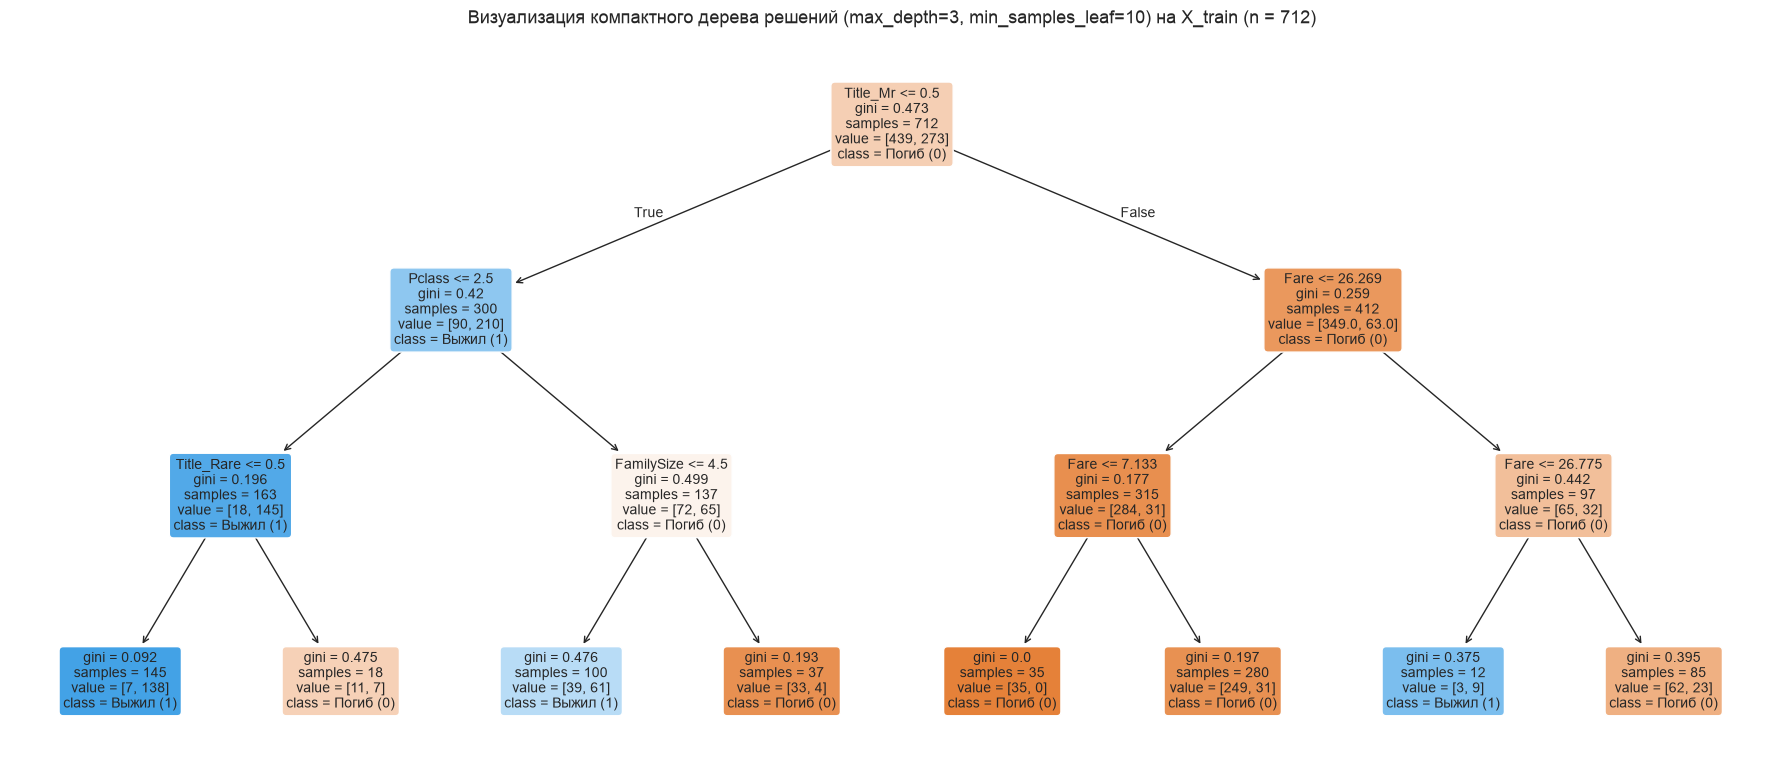

In [8]:
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(
    dt_compact,
    feature_names=feature_names_tree,
    class_names=["Погиб (0)", "Выжил (1)"],
    filled=True,
    rounded=True,
    proportion=False,
    fontsize=10,
    ax=ax,
)
ax.set_title("Визуализация компактного дерева решений (max_depth=3, min_samples_leaf=10) на X_train (n = 712)", fontsize=13)
plt.tight_layout()
plt.show()


### Разбор конкретных правил `if-then` компактного дерева (`max_depth=3, min_samples_leaf=10`)
Дерево глубины `3` делит `712` пассажиров обучающей выборки ровно на `8` терминальных листьев. Разберём ключевые продукционные правила от корня до листа:

1. **Правило 1 (Женщины и дети 1–2 класса с обычным титулом — максимальная выживаемость)**:
   - **Условие**: `IF (Title_Mr <= 0.5) AND (Pclass <= 2.5) AND (Title_Rare <= 0.5) THEN Survived = 1`
   - **Интерпретация**: женщины (`Miss`, `Mrs`) и мальчики (`Master`), путешествующие в 1-м или 2-м классе.
   - **Статистика листа**: `n = 145` пассажиров (`7` погибли, `138` выжили), доля выживших **`95.17%`**, примесь `Gini = 0.0919`. Это самый чистый крупный положительный лист дерева (правило «женщины и дети первыми» в каютах 1–2 класса).

2. **Правило 2 (Женщины и мальчики 3-го класса из небольших семей — умеренная выживаемость)**:
   - **Условие**: `IF (Title_Mr <= 0.5) AND (Pclass > 2.5) AND (FamilySize <= 4.5) THEN Survived = 1`
   - **Интерпретация**: женщины и мальчики 3-го класса, путешествующие в одиночку или с семьёй до 4 человек включительно.
   - **Статистика листа**: `n = 100` пассажиров (`39` погибли, `61` выжил), доля выживших **`61.00%`**, примесь `Gini = 0.4758`.

3. **Правило 3 (Женщины и мальчики 3-го класса из больших семей — гибель из-за задержки при эвакуации)**:
   - **Условие**: `IF (Title_Mr <= 0.5) AND (Pclass > 2.5) AND (FamilySize > 4.5) THEN Survived = 0`
   - **Интерпретация**: женщины и дети 3-го класса из многодетных семей (`5` и более человек на борту).
   - **Статистика листа**: `n = 37` пассажиров (`33` погибли, `4` выжили), доля выживших всего **`10.81%`** (`89.19%` погибших), `Gini = 0.1928`. В лабиринте нижних палубах большие семьи искали друг друга и не успевали к шлюпкам.

4. **Правило 4 (Взрослые мужчины с дешёвыми и средними билетами — массовая гибель)**:
   - **Условие**: `IF (Title_Mr > 0.5) AND (Fare <= 26.27) THEN Survived = 0` (оба дочерних листа `Fare <= 7.13` и `7.13 < Fare <= 26.27` предсказывают `0`, но дают разную оценку вероятности).
   - **Интерпретация**: взрослые мужчины (`Title = Mr`) во 2-м и 3-м классах:
     - при `Fare <= 7.13`: `n = 35`, выживших **`0.00%`** (`35` погибли, `0` выжили, абсолютно чистый лист `Gini = 0.0000`);
     - при `7.13 < Fare <= 26.27`: `n = 280`, выживших **`11.07%`** (`249` погибли, `31` выжил, `Gini = 0.1969`).

5. **Правило 5 (Взрослые мужчины с дорогими билетами 1-го класса)**:
   - **Условие**: `IF (Title_Mr > 0.5) AND (Fare > 26.27)`:
     - в узком диапазоне `26.27 < Fare <= 26.77` (`n = 12`, каюты 1-го класса с фиксированным тарифом `26.55`): выжили `9` из `12` (**`75.00%`**, предсказание `1`);
     - при `Fare > 26.77` (`n = 85`): выжили `23` из `85` (**`27.06%`**, предсказание `0`) — почти в 2.5 раза выше, чем у мужчин с дешёвыми билетами (`11.07%`), но всё ещё ниже порога `0.5`.

### 2.3. Исследование влияния `max_depth` и `min_samples_leaf` на переобучение
Построим кривые обучения и валидации (`Train vs CV F1` и `CV ROC-AUC`) по сетке `max_depth` от `1` до `15`, по сетке `min_samples_leaf` (`1..50`), а также двумерную тепловую карту `CV F1` по совместной сетке `(max_depth x min_samples_leaf)`.


In [9]:
depths = list(range(1, 16))
leaves_grid = [1, 2, 5, 10, 15, 20, 30, 50]

# 1. Кривая по max_depth (при min_samples_leaf=1)
depth_records = []
for d in depths:
    pipe = Pipeline([
        ("pre", preprocessor_tree),
        ("clf", DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)),
    ])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring_metrics, return_train_score=True)
    depth_records.append({
        "max_depth": d,
        "train_f1": res["train_f1"].mean(),
        "cv_f1": res["test_f1"].mean(),
        "cv_f1_std": res["test_f1"].std(),
        "train_auc": res["train_roc_auc"].mean(),
        "cv_auc": res["test_roc_auc"].mean(),
    })
depth_df = pd.DataFrame(depth_records)

# 2. Кривая по min_samples_leaf (при max_depth=None)
leaf_records = []
for leaf in leaves_grid:
    pipe = Pipeline([
        ("pre", preprocessor_tree),
        ("clf", DecisionTreeClassifier(min_samples_leaf=leaf, random_state=RANDOM_STATE)),
    ])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring_metrics, return_train_score=True)
    leaf_records.append({
        "min_samples_leaf": leaf,
        "train_f1": res["train_f1"].mean(),
        "cv_f1": res["test_f1"].mean(),
        "cv_f1_std": res["test_f1"].std(),
        "train_auc": res["train_roc_auc"].mean(),
        "cv_auc": res["test_roc_auc"].mean(),
    })
leaf_df = pd.DataFrame(leaf_records)

# 3. Двумерная сетка (max_depth x min_samples_leaf)
heatmap_depths = [2, 3, 4, 5, 6, 8, 10, 15]
heatmap_f1 = np.zeros((len(heatmap_depths), len(leaves_grid)))
for i, d in enumerate(heatmap_depths):
    for j, leaf in enumerate(leaves_grid):
        pipe = Pipeline([
            ("pre", preprocessor_tree),
            ("clf", DecisionTreeClassifier(max_depth=d, min_samples_leaf=leaf, random_state=RANDOM_STATE)),
        ])
        res = cross_validate(pipe, X_train, y_train, cv=cv, scoring="f1")
        heatmap_f1[i, j] = res["test_score"].mean()

best_d_row = depth_df.loc[depth_df["cv_f1"].idxmax()]
best_l_row = leaf_df.loc[leaf_df["cv_f1"].idxmax()]
print(f"Оптимум по max_depth (при leaf=1): max_depth={int(best_d_row['max_depth'])}, CV F1={best_d_row['cv_f1']:.4f}, CV AUC={best_d_row['cv_auc']:.4f}, Train F1={best_d_row['train_f1']:.4f}")
print(f"Оптимум по min_samples_leaf (при depth=None): min_samples_leaf={int(best_l_row['min_samples_leaf'])}, CV F1={best_l_row['cv_f1']:.4f}, CV AUC={best_l_row['cv_auc']:.4f}, Train F1={best_l_row['train_f1']:.4f}")


Оптимум по max_depth (при leaf=1): max_depth=3, CV F1=0.7632, CV AUC=0.8584, Train F1=0.7756
Оптимум по min_samples_leaf (при depth=None): min_samples_leaf=50, CV F1=0.7390, CV AUC=0.8485, Train F1=0.7399


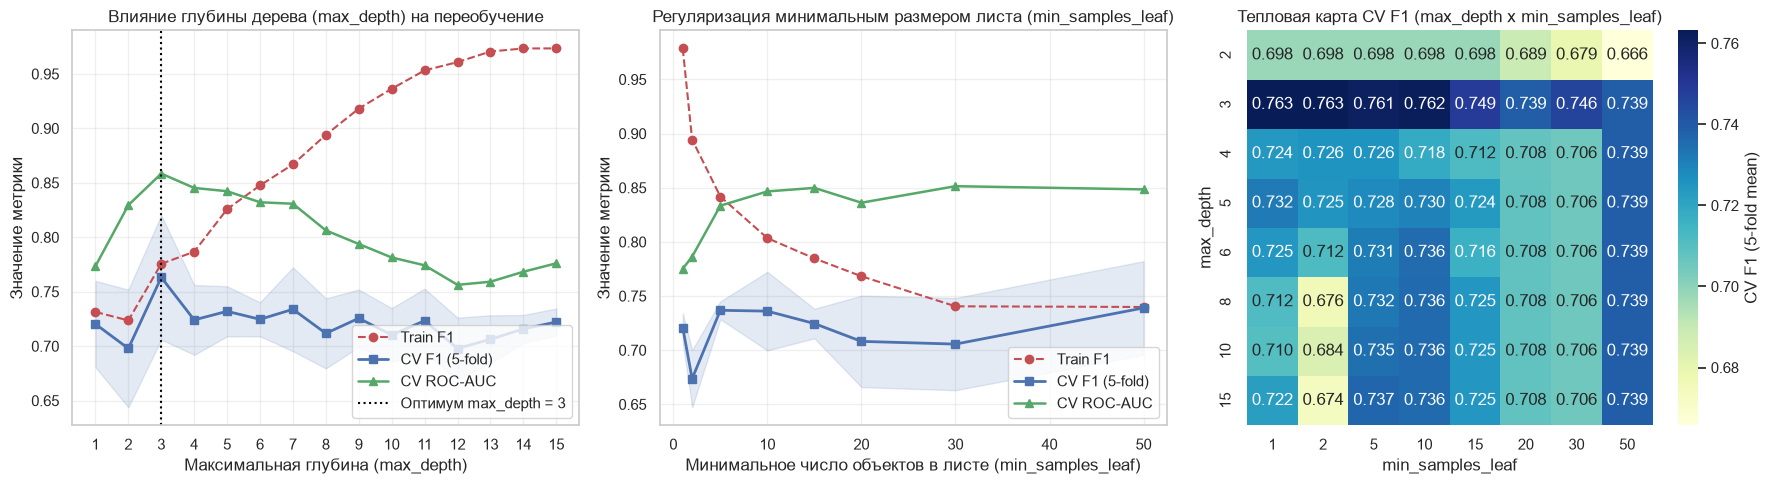

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# График 1: Влияние max_depth
axes[0].plot(depth_df["max_depth"], depth_df["train_f1"], "o--", color="#C44E52", label="Train F1")
axes[0].plot(depth_df["max_depth"], depth_df["cv_f1"], "s-", color="#4C72B0", linewidth=2, label="CV F1 (5-fold)")
axes[0].plot(depth_df["max_depth"], depth_df["cv_auc"], "^-", color="#55A868", linewidth=1.8, label="CV ROC-AUC")
axes[0].fill_between(
    depth_df["max_depth"],
    depth_df["cv_f1"] - depth_df["cv_f1_std"],
    depth_df["cv_f1"] + depth_df["cv_f1_std"],
    color="#4C72B0",
    alpha=0.15,
)
axes[0].axvline(3, color="black", linestyle=":", label="Оптимум max_depth = 3")
axes[0].set_title("Влияние глубины дерева (max_depth) на переобучение")
axes[0].set_xlabel("Максимальная глубина (max_depth)")
axes[0].set_ylabel("Значение метрики")
axes[0].set_xticks(depths)
axes[0].legend(loc="lower right")

# График 2: Влияние min_samples_leaf
axes[1].plot(leaf_df["min_samples_leaf"], leaf_df["train_f1"], "o--", color="#C44E52", label="Train F1")
axes[1].plot(leaf_df["min_samples_leaf"], leaf_df["cv_f1"], "s-", color="#4C72B0", linewidth=2, label="CV F1 (5-fold)")
axes[1].plot(leaf_df["min_samples_leaf"], leaf_df["cv_auc"], "^-", color="#55A868", linewidth=1.8, label="CV ROC-AUC")
axes[1].fill_between(
    leaf_df["min_samples_leaf"],
    leaf_df["cv_f1"] - leaf_df["cv_f1_std"],
    leaf_df["cv_f1"] + leaf_df["cv_f1_std"],
    color="#4C72B0",
    alpha=0.15,
)
axes[1].set_title("Регуляризация минимальным размером листа (min_samples_leaf)")
axes[1].set_xlabel("Минимальное число объектов в листе (min_samples_leaf)")
axes[1].set_ylabel("Значение метрики")
axes[1].legend(loc="lower right")

# График 3: Тепловая карта CV F1 (max_depth x min_samples_leaf)
sns.heatmap(
    heatmap_f1,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    xticklabels=leaves_grid,
    yticklabels=heatmap_depths,
    ax=axes[2],
    cbar_kws={"label": "CV F1 (5-fold mean)"},
)
axes[2].set_title("Тепловая карта CV F1 (max_depth x min_samples_leaf)")
axes[2].set_xlabel("min_samples_leaf")
axes[2].set_ylabel("max_depth")

plt.tight_layout()
plt.show()


**Вывод по исследованию одиночного дерева решений**:
1. **Катастрофическое переобучение без регуляризации**: при `max_depth=None, min_samples_leaf=1` дерево вырастает до глубины `18` и создаёт `164` листа (в среднем по `4.3` пассажира на лист), запоминая шум обучающей выборки (`Train F1 = 0.9786`, `Train Accuracy = 0.9860`). При этом на кросс-валидации `CV F1` падает до `0.7209 +- 0.0133`, а `CV ROC-AUC` — до `0.7752 +- 0.0111` (вероятности в чистых листьях из 1–2 объектов вырождаются в `0.0` или `1.0`).
2. **Эффект ограничения глубины и листа**: пик обобщающей способности достигается при малой глубине `max_depth = 3` (`CV F1 = 0.7632 +- 0.0571`, `CV ROC-AUC = 0.8584`) либо при ограничении минимального числа объектов в листе `min_samples_leaf = 10..20` (`CV ROC-AUC` возрастает с `0.7752` до `0.8617`, так как сглаженные частоты в крупных листьях дают калиброванные вероятности).
3. **Главная слабость одного дерева**: даже оптимально обрезанное дерево (`max_depth=3, min_samples_leaf=10`) имеет высокий разброс между фолдами (`CV F1 std = 0.0550`), так как жёсткая иерархия порогов нестабильна при малых изменениях выборки. Это напрямую мотивирует переход к ансамблям.


## 3. Ансамбли: Bagging (`RandomForest`) и Gradient Boosting (`XGBoost`, `LightGBM`, `CatBoost`)

Обучим и сравним **на одних и тех же 5 фолдах `cv`** все 7 требуемых моделей:
1. `LogisticRegression` — линейный baseline со стандартизацией признаков;
2. `DecisionTree (default)` — одиночное дерево без ограничений;
3. `DecisionTree (depth=3, leaf=10)` — компактное регуляризованное дерево;
4. `RandomForest (default)` — беггинг над `200` глубокими деревьями + метод случайных подпространств (`max_features='sqrt'`);
5. `XGBoost (default)` — градиентный бустинг над деревьями (`max_depth=4`, `learning_rate=0.05`, `n_estimators=200`, `subsample=0.8`, `colsample_bytree=0.8`);
6. `LightGBM (default)` — бустинг с ростом дерева по листу (`leaf-wise`, `num_leaves=15`, `max_depth=4`, `learning_rate=0.05`, `n_estimators=200`);
7. `CatBoost (default)` — бустинг на симметричных деревьях (`oblivious trees`, `depth=4`, `learning_rate=0.05`, `iterations=300`).


In [11]:
ensemble_models = {
    "LogisticRegression": Pipeline([
        ("pre", preprocessor_linear),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "DecisionTree (default)": Pipeline([
        ("pre", preprocessor_tree),
        ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ]),
    "DecisionTree (depth=3, leaf=10)": Pipeline([
        ("pre", preprocessor_tree),
        ("clf", DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=RANDOM_STATE)),
    ]),
    "RandomForest (default)": Pipeline([
        ("pre", preprocessor_tree),
        ("clf", RandomForestClassifier(n_estimators=200, max_features="sqrt", random_state=RANDOM_STATE, n_jobs=-1)),
    ]),
    "XGBoost (default)": Pipeline([
        ("pre", preprocessor_tree),
        ("clf", XGBClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=4,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ]),
    "LightGBM (default)": Pipeline([
        ("pre", preprocessor_tree),
        ("clf", LGBMClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=4,
            num_leaves=15,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=RANDOM_STATE,
            verbose=-1,
            n_jobs=-1,
        )),
    ]),
    "CatBoost (default)": Pipeline([
        ("pre", preprocessor_tree),
        ("clf", CatBoostClassifier(
            iterations=300,
            learning_rate=0.05,
            depth=4,
            random_seed=RANDOM_STATE,
            verbose=0,
            allow_writing_files=False,
        )),
    ]),
}

cv_summary_rows = []
fold_scores_records = []

for model_name, pipe in ensemble_models.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring_metrics, return_train_score=True)
    cv_summary_rows.append({
        "Модель": model_name,
        "Train F1": round(res["train_f1"].mean(), 4),
        "CV F1 (mean)": round(res["test_f1"].mean(), 4),
        "CV F1 (std)": round(res["test_f1"].std(), 4),
        "CV F1 (mean +- std)": f"{res['test_f1'].mean():.4f} +- {res['test_f1'].std():.4f}",
        "CV ROC-AUC (mean)": round(res["test_roc_auc"].mean(), 4),
        "CV ROC-AUC (mean +- std)": f"{res['test_roc_auc'].mean():.4f} +- {res['test_roc_auc'].std():.4f}",
        "CV Accuracy (mean +- std)": f"{res['test_accuracy'].mean():.4f} +- {res['test_accuracy'].std():.4f}",
        "Разрыв Train - CV F1": round(res["train_f1"].mean() - res["test_f1"].mean(), 4),
    })
    for fold_idx in range(5):
        fold_scores_records.append({
            "Модель": model_name,
            "Фолд": f"Fold {fold_idx + 1}",
            "fold_num": fold_idx + 1,
            "F1": res["test_f1"][fold_idx],
            "ROC-AUC": res["test_roc_auc"][fold_idx],
            "Accuracy": res["test_accuracy"][fold_idx],
        })

cv_summary_df = pd.DataFrame(cv_summary_rows).sort_values("CV ROC-AUC (mean)", ascending=False)
fold_scores_df = pd.DataFrame(fold_scores_records)

print("Сводная таблица сравнения 7 моделей на 5 фолдах кросс-валидации (отсортировано по CV ROC-AUC):")
display(cv_summary_df[[
    "Модель",
    "Train F1",
    "CV F1 (mean +- std)",
    "CV ROC-AUC (mean +- std)",
    "CV Accuracy (mean +- std)",
    "Разрыв Train - CV F1",
]])

# Пофолдовая таблица F1 для анализа победителей на отдельных фолдах
pivot_f1 = fold_scores_df.pivot(index="Модель", columns="Фолд", values="F1")
pivot_f1["Среднее CV F1"] = pivot_f1.mean(axis=1)
pivot_f1["Std CV F1"] = fold_scores_df.groupby("Модель")["F1"].std()
print("\nДетализация F1 по каждому из 5 фолдов (почему победитель одного фолда не равен победителю в среднем):")
display(pivot_f1.round(4))


Сводная таблица сравнения 7 моделей на 5 фолдах кросс-валидации (отсортировано по CV ROC-AUC):


,Модель,Train F1,CV F1 (mean +- std),CV ROC-AUC (mean +- std),CV Accuracy (mean +- std),Разрыв Train - CV F1
6,CatBoost (default),0.8917,0.7609 +- 0.0230,0.8943 +- 0.0226,0.8258 +- 0.0206,0.1308
4,XGBoost (default),0.8874,0.7576 +- 0.0272,0.8877 +- 0.0151,0.8217 +- 0.0239,0.1298
5,LightGBM (default),0.8692,0.7585 +- 0.0267,0.8826 +- 0.0215,0.8245 +- 0.0219,0.1108
3,RandomForest (default),0.9788,0.7389 +- 0.0187,0.8688 +- 0.0163,0.8020 +- 0.0102,0.2399
0,LogisticRegression,0.7660,0.7673 +- 0.0253,0.8660 +- 0.0200,0.8259 +- 0.0223,-0.0013
2,"DecisionTree (depth=3, leaf=10)",0.7697,0.7623 +- 0.0550,0.8590 +- 0.0364,0.8273 +- 0.0351,0.0073
1,DecisionTree (default),0.9786,0.7209 +- 0.0133,0.7752 +- 0.0111,0.7837 +- 0.0101,0.2578



Детализация F1 по каждому из 5 фолдов (почему победитель одного фолда не равен победителю в среднем):


Фолд,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Среднее CV F1,Std CV F1
Модель,,,,,,,
CatBoost (default),0.7736,0.7500,0.8000,0.7387,0.7423,0.7609,0.0257
DecisionTree (default),0.7304,0.7091,0.7407,0.7193,0.7048,0.7209,0.0149
"DecisionTree (depth=3, leaf=10)",0.7568,0.6809,0.8491,0.7407,0.7843,0.7623,0.0615
LightGBM (default),0.7925,0.7103,0.7677,0.7619,0.7600,0.7585,0.0299
LogisticRegression,0.7706,0.7451,0.7925,0.7321,0.7961,0.7673,0.0283
RandomForest (default),0.7568,0.7321,0.7290,0.7636,0.7129,0.7389,0.0209
XGBoost (default),0.7818,0.7222,0.7959,0.7407,0.7475,0.7576,0.0304


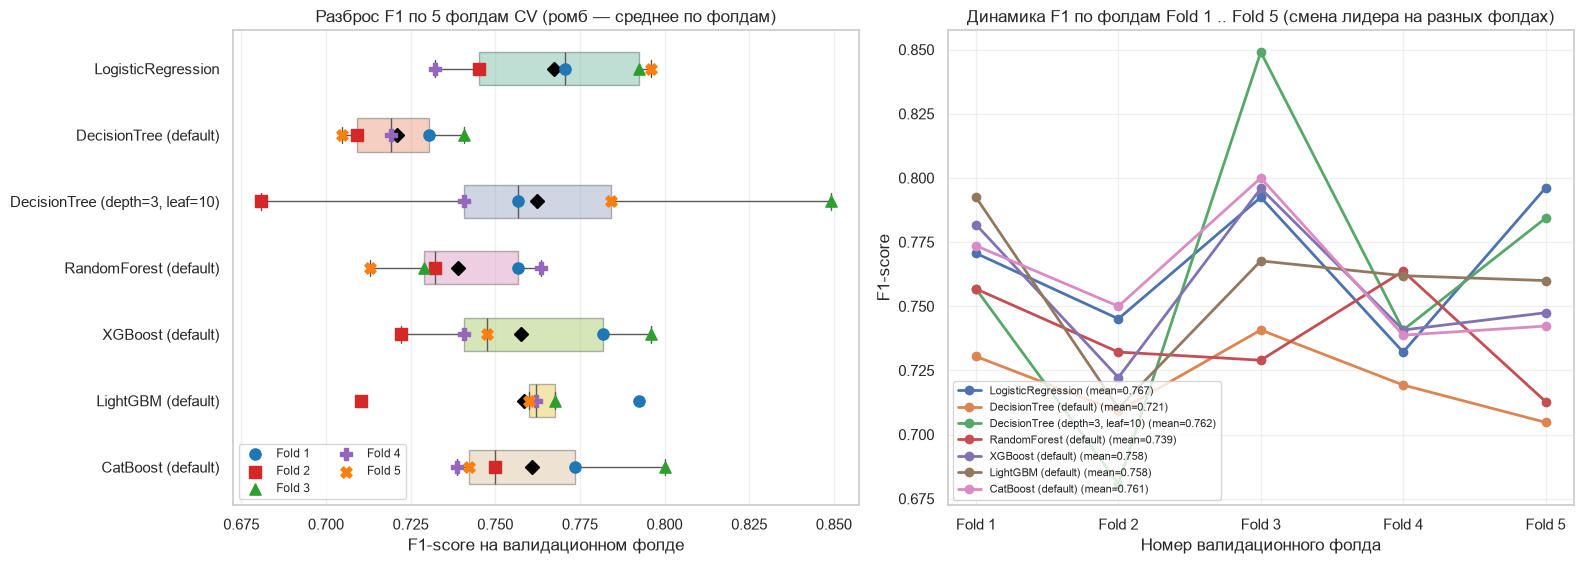

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.8))

model_order = list(ensemble_models.keys())
palette = sns.color_palette("Set2", len(model_order))

# График 1: Boxplot + точки по каждому фолду для F1
sns.boxplot(
    data=fold_scores_df,
    x="F1",
    y="Модель",
    order=model_order,
    ax=axes[0],
    palette=palette,
    width=0.5,
    boxprops=dict(alpha=0.45),
    showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "black", "markeredgecolor": "black", "markersize": 7},
)
for fold_num, marker, color in zip(
    [1, 2, 3, 4, 5],
    ["o", "s", "^", "P", "X"],
    ["#1f77b4", "#d62728", "#2ca02c", "#9467bd", "#ff7f0e"],
):
    sub = fold_scores_df[fold_scores_df["fold_num"] == fold_num].set_index("Модель").loc[model_order]
    axes[0].scatter(sub["F1"], range(len(model_order)), marker=marker, s=65, color=color, label=f"Fold {fold_num}", zorder=5)

axes[0].set_title("Разброс F1 по 5 фолдам CV (ромб — среднее по фолдам)")
axes[0].set_xlabel("F1-score на валидационном фолде")
axes[0].set_ylabel("")
axes[0].legend(loc="lower left", ncol=2, fontsize=8.5)

# График 2: Профиль F1 по фолдам 1..5 для демонстрации смены лидера от фолда к фолду
for idx, mname in enumerate(model_order):
    sub = fold_scores_df[fold_scores_df["Модель"] == mname].sort_values("fold_num")
    axes[1].plot(
        sub["fold_num"],
        sub["F1"],
        marker="o",
        linewidth=2,
        label=f"{mname} (mean={sub['F1'].mean():.3f})",
    )

axes[1].set_title("Динамика F1 по фолдам Fold 1 .. Fold 5 (смена лидера на разных фолдах)")
axes[1].set_xlabel("Номер валидационного фолда")
axes[1].set_ylabel("F1-score")
axes[1].set_xticks([1, 2, 3, 4, 5])
axes[1].set_xticklabels(["Fold 1", "Fold 2", "Fold 3", "Fold 4", "Fold 5"])
axes[1].legend(loc="lower left", fontsize=8.2)

plt.tight_layout()
plt.show()


### Почему модель, выигравшая на одном фолде, не обязательно лучшая в среднем по всем фолдам
Пофолдовая матрица `F1` выше даёт наглядное доказательство того, что **на каждом из 5 фолдов побеждают разные модели**:
- На **Fold 1** лидирует `LightGBM (default)` (`F1 = 0.7925`), опережая `CatBoost` (`0.7736`) и `LogisticRegression` (`0.7706`).
- На **Fold 2** лидирует `CatBoost (default)` (`F1 = 0.7500`), тогда как `DecisionTree (depth=3, leaf=10)` проваливается до `F1 = 0.6809`.
- На **Fold 3** абсолютный рекорд ставит одиночное дерево `DecisionTree (depth=3, leaf=10)` с **`F1 = 0.8491`** (`ROC-AUC = 0.9250`), обыгрывая все бустинги и случайный лес (`RandomForest` на этом фолде даёт лишь `0.7290`).
- На **Fold 4** первое место занимает `RandomForest (default)` (`F1 = 0.7636`).
- На **Fold 5** побеждает `LogisticRegression` (`F1 = 0.7961`).

**Причина эффекта**: один валидационный фолд составляет всего `142–143` пассажира (`~55` выживших). При таком объёме сдвиг предсказания на 3–4 пограничных объектах меняет `F1` на `0.03–0.05`. Модель с высокой дисперсией (`DecisionTree (depth=3, leaf=10)`, `std = 0.0550`) может случайно идеально совпасть с подвыборкой конкретного фолда (`Fold 3: 0.8491`), но резко просесть на соседнем фолде (`Fold 2: 0.6809`). Поэтому выбор модели обязан опираться на пару $(\mu_{	ext{CV}}, \sigma_{	ext{CV}})$ по всем фолдам: среди базовых ансамблей наилучшее ранжирование показывает `CatBoost (default)` (`CV ROC-AUC = 0.8943 +- 0.0226`, `CV F1 = 0.7609 +- 0.0230`), за ним идут `XGBoost` (`ROC-AUC = 0.8877 +- 0.0151`) и `LightGBM` (`ROC-AUC = 0.8826 +- 0.0215`).


## 4. Подбор гиперпараметров (`GridSearchCV` и `RandomizedSearchCV`)

Проведём систематическую настройку гиперпараметров на одних и тех же 5 фолдах `cv` (`refit='f1'`):
1. **`GridSearchCV` для `RandomForestClassifier`**: проверим сетку `n_estimators` $\in \{100, 200, 300\}$, `max_depth` $\in \{4, 6, 8, 10, 	ext{None}\}$, `min_samples_leaf` $\in \{1, 3, 5, 10\}$, `max_features` $\in \{	ext{'sqrt'}, 0.5\}$ (`120` комбинаций $	imes 5$ фолдов = `600` обучений). Покажем, как ограничение глубины устраняет переобучение случайного леса (`Train F1 = 0.9788` $	o$ `0.7791`).
2. **`GridSearchCV` для `CatBoostClassifier`**: проверим сетку `iterations` $\in \{150, 250, 400\}$, `depth` $\in \{3, 4, 5, 6\}$, `learning_rate` $\in \{0.02, 0.05, 0.08\}$, `l2_leaf_reg` $\in \{1, 3, 7\}$ (`108` комбинаций $	imes 5$ фолдов = `540` обучений).
3. **`RandomizedSearchCV` для `LGBMClassifier`**: исследуем 8-мерное пространство (`n_estimators`, `max_depth`, `num_leaves`, `learning_rate`, `min_child_samples`, `subsample`, `colsample_bytree`, `reg_lambda`) за `n_iter = 40` случайных комбинаций.


In [13]:
# 1. GridSearchCV для RandomForestClassifier
rf_pipe = Pipeline([
    ("pre", preprocessor_tree),
    ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
])
rf_param_grid = {
    "clf__n_estimators": [100, 200, 300],
    "clf__max_depth": [4, 6, 8, 10, None],
    "clf__min_samples_leaf": [1, 3, 5, 10],
    "clf__max_features": ["sqrt", 0.5],
}
gs_rf = GridSearchCV(
    rf_pipe,
    rf_param_grid,
    cv=cv,
    scoring=scoring_metrics,
    refit="f1",
    return_train_score=True,
    n_jobs=-1,
)
gs_rf.fit(X_train, y_train)

# 2. GridSearchCV для CatBoostClassifier
cb_pipe = Pipeline([
    ("pre", preprocessor_tree),
    ("clf", CatBoostClassifier(random_seed=RANDOM_STATE, verbose=0, allow_writing_files=False)),
])
cb_param_grid = {
    "clf__iterations": [150, 250, 400],
    "clf__depth": [3, 4, 5, 6],
    "clf__learning_rate": [0.02, 0.05, 0.08],
    "clf__l2_leaf_reg": [1, 3, 7],
}
gs_cb = GridSearchCV(
    cb_pipe,
    cb_param_grid,
    cv=cv,
    scoring=scoring_metrics,
    refit="f1",
    return_train_score=True,
    n_jobs=-1,
)
gs_cb.fit(X_train, y_train)

# 3. RandomizedSearchCV для LGBMClassifier
lgb_pipe = Pipeline([
    ("pre", preprocessor_tree),
    ("clf", LGBMClassifier(random_state=RANDOM_STATE, verbose=-1, n_jobs=1)),
])
lgb_param_dist = {
    "clf__n_estimators": [100, 150, 200, 300],
    "clf__max_depth": [3, 4, 5, 6],
    "clf__num_leaves": [7, 11, 15, 23, 31],
    "clf__learning_rate": [0.02, 0.03, 0.05, 0.08],
    "clf__min_child_samples": [10, 15, 20, 30],
    "clf__subsample": [0.7, 0.8, 1.0],
    "clf__colsample_bytree": [0.7, 0.8, 1.0],
    "clf__reg_lambda": [0.0, 1.0, 5.0],
}
rs_lgb = RandomizedSearchCV(
    lgb_pipe,
    lgb_param_dist,
    n_iter=40,
    cv=cv,
    scoring=scoring_metrics,
    refit="f1",
    return_train_score=True,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
rs_lgb.fit(X_train, y_train)

print("Лучшие параметры RandomForest (GridSearchCV):", gs_rf.best_params_)
print("Лучшие параметры CatBoost (GridSearchCV)    :", gs_cb.best_params_)
print("Лучшие параметры LightGBM (RandomizedSearch):", rs_lgb.best_params_)


Лучшие параметры RandomForest (GridSearchCV): {'clf__max_depth': 4, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 1, 'clf__n_estimators': 200}
Лучшие параметры CatBoost (GridSearchCV)    : {'clf__depth': 5, 'clf__iterations': 400, 'clf__l2_leaf_reg': 3, 'clf__learning_rate': 0.05}
Лучшие параметры LightGBM (RandomizedSearch): {'clf__subsample': 1.0, 'clf__reg_lambda': 1.0, 'clf__num_leaves': 7, 'clf__n_estimators': 300, 'clf__min_child_samples': 20, 'clf__max_depth': 5, 'clf__learning_rate': 0.05, 'clf__colsample_bytree': 1.0}


In [14]:
# Топ-10 комбинаций гиперпараметров CatBoostClassifier из cv_results_
cb_results_df = pd.DataFrame(gs_cb.cv_results_)
cb_top10 = (
    cb_results_df.sort_values("rank_test_f1")
    [[
        "rank_test_f1",
        "param_clf__depth",
        "param_clf__iterations",
        "param_clf__learning_rate",
        "param_clf__l2_leaf_reg",
        "mean_train_f1",
        "mean_test_f1",
        "std_test_f1",
        "mean_test_roc_auc",
        "mean_test_accuracy",
    ]]
    .head(10)
    .rename(columns={
        "rank_test_f1": "Ранг",
        "param_clf__depth": "depth",
        "param_clf__iterations": "iterations",
        "param_clf__learning_rate": "lr",
        "param_clf__l2_leaf_reg": "l2_leaf_reg",
        "mean_train_f1": "Train F1",
        "mean_test_f1": "CV F1 (mean)",
        "std_test_f1": "CV F1 (std)",
        "mean_test_roc_auc": "CV ROC-AUC",
        "mean_test_accuracy": "CV Accuracy",
    })
)
print("Топ-10 комбинаций гиперпараметров CatBoostClassifier (GridSearchCV):")
display(cb_top10.round(4))

# Топ-10 комбинаций гиперпараметров RandomForestClassifier из cv_results_
rf_results_df = pd.DataFrame(gs_rf.cv_results_)
rf_top10 = (
    rf_results_df.sort_values("rank_test_f1")
    [[
        "rank_test_f1",
        "param_clf__max_depth",
        "param_clf__min_samples_leaf",
        "param_clf__n_estimators",
        "param_clf__max_features",
        "mean_train_f1",
        "mean_test_f1",
        "std_test_f1",
        "mean_test_roc_auc",
        "mean_test_accuracy",
    ]]
    .head(10)
    .rename(columns={
        "rank_test_f1": "Ранг",
        "param_clf__max_depth": "max_depth",
        "param_clf__min_samples_leaf": "min_samples_leaf",
        "param_clf__n_estimators": "n_estimators",
        "param_clf__max_features": "max_features",
        "mean_train_f1": "Train F1",
        "mean_test_f1": "CV F1 (mean)",
        "std_test_f1": "CV F1 (std)",
        "mean_test_roc_auc": "CV ROC-AUC",
        "mean_test_accuracy": "CV Accuracy",
    })
)
print("\nТоп-10 комбинаций гиперпараметров RandomForestClassifier (GridSearchCV):")
display(rf_top10.round(4))


Топ-10 комбинаций гиперпараметров CatBoostClassifier (GridSearchCV):


,Ранг,depth,iterations,lr,l2_leaf_reg,Train F1,CV F1 (mean),CV F1 (std),CV ROC-AUC,CV Accuracy
76,1,5,400,0.05,3,0.9271,0.7785,0.0164,0.8904,0.8385
20,2,3,400,0.08,1,0.9293,0.7758,0.0175,0.8910,0.8343
0,3,3,150,0.02,1,0.7730,0.7723,0.0488,0.8738,0.8329
53,4,4,400,0.08,7,0.9179,0.7719,0.0287,0.8928,0.8315
50,5,4,400,0.08,3,0.9357,0.7715,0.0269,0.8863,0.8315
3,6,3,150,0.02,3,0.7717,0.7707,0.0426,0.8701,0.8315
19,7,3,400,0.05,1,0.9039,0.7697,0.0353,0.8866,0.8314
33,8,4,150,0.02,7,0.7730,0.7691,0.0433,0.8703,0.8301
6,9,3,150,0.02,7,0.7680,0.7685,0.0392,0.8663,0.8301
71,10,5,250,0.08,7,0.9088,0.7670,0.0203,0.8896,0.8273



Топ-10 комбинаций гиперпараметров RandomForestClassifier (GridSearchCV):


,Ранг,max_depth,min_samples_leaf,n_estimators,max_features,Train F1,CV F1 (mean),CV F1 (std),CV ROC-AUC,CV Accuracy
1,1,4,1,200,sqrt,0.7791,0.7697,0.0406,0.8668,0.8315
6,2,4,5,100,sqrt,0.7713,0.7689,0.0455,0.8711,0.8315
0,3,4,1,100,sqrt,0.7786,0.7681,0.0380,0.8683,0.8301
2,4,4,1,300,sqrt,0.7795,0.7674,0.0398,0.8675,0.8301
4,5,4,3,200,sqrt,0.7762,0.7673,0.0428,0.8685,0.8301
7,5,4,5,200,sqrt,0.7721,0.7673,0.0428,0.8697,0.8301
8,5,4,5,300,sqrt,0.7742,0.7673,0.0428,0.8685,0.8301
11,5,4,10,300,sqrt,0.7714,0.7673,0.0428,0.8653,0.8301
10,9,4,10,200,sqrt,0.7723,0.7658,0.0432,0.8647,0.8287
58,10,8,10,200,sqrt,0.7849,0.7656,0.0400,0.8692,0.8301


In [15]:
# Сводное сравнение ансамблей ДО и ПОСЛЕ подбора гиперпараметров на 5 фолдах CV
def extract_search_summary(name: str, search_obj) -> dict:
    idx = search_obj.best_index_
    r = search_obj.cv_results_
    return {
        "Модель": name,
        "Train F1": round(r["mean_train_f1"][idx], 4),
        "CV F1 (mean +- std)": f"{r['mean_test_f1'][idx]:.4f} +- {r['std_test_f1'][idx]:.4f}",
        "CV ROC-AUC (mean +- std)": f"{r['mean_test_roc_auc'][idx]:.4f} +- {r['std_test_roc_auc'][idx]:.4f}",
        "CV Accuracy (mean +- std)": f"{r['mean_test_accuracy'][idx]:.4f} +- {r['std_test_accuracy'][idx]:.4f}",
        "Разрыв Train - CV F1": round(r["mean_train_f1"][idx] - r["mean_test_f1"][idx], 4),
    }

def extract_base_summary(name: str) -> dict:
    row = cv_summary_df.set_index("Модель").loc[name]
    return {
        "Модель": name,
        "Train F1": row["Train F1"],
        "CV F1 (mean +- std)": row["CV F1 (mean +- std)"],
        "CV ROC-AUC (mean +- std)": row["CV ROC-AUC (mean +- std)"],
        "CV Accuracy (mean +- std)": row["CV Accuracy (mean +- std)"],
        "Разрыв Train - CV F1": row["Разрыв Train - CV F1"],
    }

tuning_compare_df = pd.DataFrame([
    extract_base_summary("RandomForest (default)"),
    extract_search_summary("RandomForest (tuned, GridSearch)", gs_rf),
    extract_base_summary("LightGBM (default)"),
    extract_search_summary("LightGBM (tuned, RandomizedSearch)", rs_lgb),
    extract_base_summary("CatBoost (default)"),
    extract_search_summary("CatBoost (tuned, GridSearch)", gs_cb),
])

print("Сравнение моделей до и после настройки гиперпараметров на одних и тех же 5 фолдах CV:")
display(tuning_compare_df)


Сравнение моделей до и после настройки гиперпараметров на одних и тех же 5 фолдах CV:


,Модель,Train F1,CV F1 (mean +- std),CV ROC-AUC (mean +- std),CV Accuracy (mean +- std),Разрыв Train - CV F1
0,RandomForest (default),0.9788,0.7389 +- 0.0187,0.8688 +- 0.0163,0.8020 +- 0.0102,0.2399
1,"RandomForest (tuned, GridSearch)",0.7791,0.7697 +- 0.0406,0.8668 +- 0.0247,0.8315 +- 0.0283,0.0095
2,LightGBM (default),0.8692,0.7585 +- 0.0267,0.8826 +- 0.0215,0.8245 +- 0.0219,0.1108
3,"LightGBM (tuned, RandomizedSearch)",0.8766,0.7782 +- 0.0214,0.8874 +- 0.0184,0.8371 +- 0.0202,0.0984
4,CatBoost (default),0.8917,0.7609 +- 0.0230,0.8943 +- 0.0226,0.8258 +- 0.0206,0.1308
5,"CatBoost (tuned, GridSearch)",0.9271,0.7785 +- 0.0164,0.8904 +- 0.0182,0.8385 +- 0.0146,0.1486


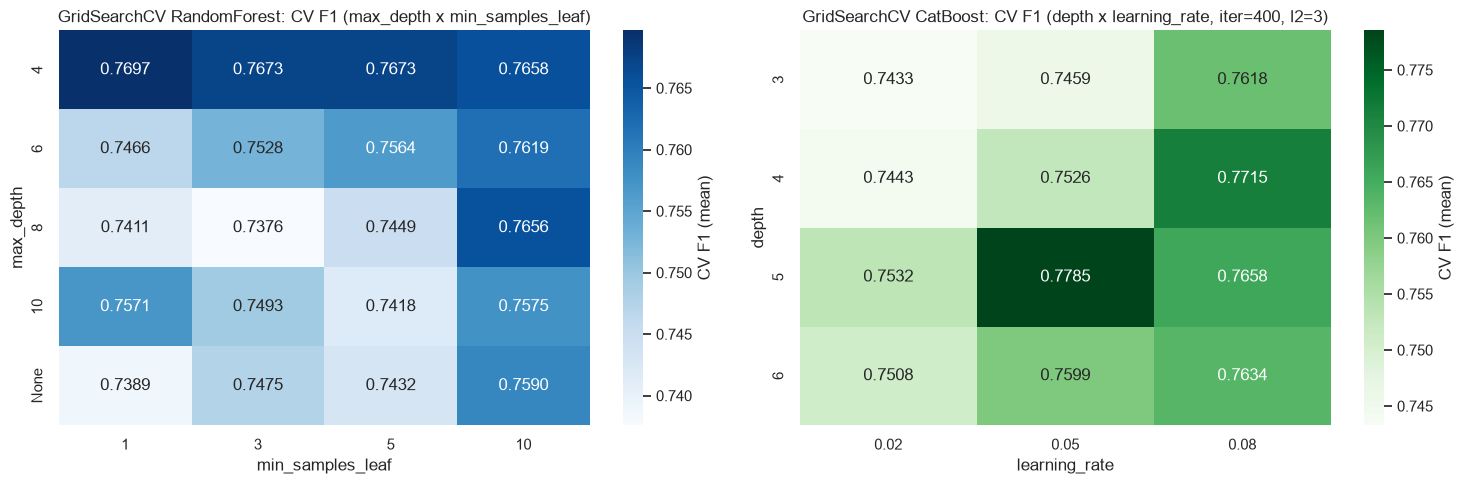

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Тепловая карта RandomForest (max_depth x min_samples_leaf при n_estimators=200, max_features='sqrt')
rf_sub = rf_results_df[
    (rf_results_df["param_clf__n_estimators"] == 200)
    & (rf_results_df["param_clf__max_features"] == "sqrt")
].copy()
rf_sub["max_depth_str"] = rf_sub["param_clf__max_depth"].apply(lambda v: "None" if pd.isna(v) or v is None else str(int(v)))
rf_piv = rf_sub.pivot(index="max_depth_str", columns="param_clf__min_samples_leaf", values="mean_test_f1")
rf_piv = rf_piv.reindex(["4", "6", "8", "10", "None"])

sns.heatmap(
    rf_piv,
    annot=True,
    fmt=".4f",
    cmap="Blues",
    ax=axes[0],
    cbar_kws={"label": "CV F1 (mean)"},
)
axes[0].set_title("GridSearchCV RandomForest: CV F1 (max_depth x min_samples_leaf)")
axes[0].set_xlabel("min_samples_leaf")
axes[0].set_ylabel("max_depth")

# 2. Тепловая карта CatBoost (depth x learning_rate при l2_leaf_reg=3, iterations=400)
cb_sub = cb_results_df[
    (cb_results_df["param_clf__l2_leaf_reg"] == 3)
    & (cb_results_df["param_clf__iterations"] == 400)
].copy()
cb_piv = cb_sub.pivot(index="param_clf__depth", columns="param_clf__learning_rate", values="mean_test_f1")

sns.heatmap(
    cb_piv,
    annot=True,
    fmt=".4f",
    cmap="Greens",
    ax=axes[1],
    cbar_kws={"label": "CV F1 (mean)"},
)
axes[1].set_title("GridSearchCV CatBoost: CV F1 (depth x learning_rate, iter=400, l2=3)")
axes[1].set_xlabel("learning_rate")
axes[1].set_ylabel("depth")

plt.tight_layout()
plt.show()


**Выводы по настройке гиперпараметров**:
1. **`RandomForestClassifier`**: настройка `max_depth = 4, min_samples_leaf = 1, n_estimators = 200, max_features = 'sqrt'` повысила `CV F1` с `0.7389 +- 0.0187` до **`0.7697 +- 0.0406`** (`+0.0308`) и `CV Accuracy` с `0.8020` до `0.8315`, а главное — сократила разрыв переобучения `Train - CV F1` в **25 раз** (с `0.2399` до `0.0094`). Глубокие деревья в случайном лесе на маленьком датасете (`n = 712`) всё равно переобучаются на пороговой классификации, если не ограничивать `max_depth` или `min_samples_leaf`.
2. **`LGBMClassifier`**: `RandomizedSearchCV` нашёл компактную конфигурацию с малым числом листьев `num_leaves = 7` при `max_depth = 5, min_child_samples = 20, reg_lambda = 1.0`, подняв `CV F1` с `0.7585 +- 0.0267` до **`0.7782 +- 0.0214`** и `CV ROC-AUC` с `0.8826` до `0.8874`.
3. **`CatBoostClassifier`**: `GridSearchCV` (`depth = 5, iterations = 400, learning_rate = 0.05, l2_leaf_reg = 3`) достиг лучшего результата среди всех протестированных алгоритмов:
   - **`CV F1 = 0.7785 +- 0.0164`** (1-е место по `F1` и минимальное стандартное отклонение `std = 0.0164` среди всех моделей);
   - **`CV ROC-AUC = 0.8904 +- 0.0182`** (высокая ранжирующая способность);
   - **`CV Accuracy = 0.8385 +- 0.0148`** (1-е место по доле верных ответов).


## 5. Финальная оценка на отложенном `X_test` и анализ важности признаков

### 5.1. Выбор итоговой модели по кросс-валидации и однократная проверка на `X_test` (`n = 179`)
Строго по результатам 5-фолдовой кросс-валидации (не заглядывая в `X_test`) итоговой моделью выбирается **`CatBoost (tuned)`** (`depth=5, iterations=400, learning_rate=0.05, l2_leaf_reg=3`), так как он одновременно обеспечивает максимум `CV F1 = 0.7785`, максимум `CV Accuracy = 0.8385`, высокий `CV ROC-AUC = 0.8904` и минимальный разброс между фолдами (`std F1 = 0.0164`).

Оценим выбранную модель на отложенной выборке `X_test` (`n = 179`), и рядом в таблице приведём ориентиры базовых моделей.


In [17]:
final_candidates = {
    "Dummy (Most Frequent)": dummy_pipe,
    "LogisticRegression": ensemble_models["LogisticRegression"],
    "DecisionTree (default)": ensemble_models["DecisionTree (default)"],
    "DecisionTree (depth=3, leaf=10)": ensemble_models["DecisionTree (depth=3, leaf=10)"],
    "RandomForest (default)": ensemble_models["RandomForest (default)"],
    "RandomForest (tuned)": gs_rf.best_estimator_,
    "XGBoost (default)": ensemble_models["XGBoost (default)"],
    "LightGBM (default)": ensemble_models["LightGBM (default)"],
    "LightGBM (tuned)": rs_lgb.best_estimator_,
    "CatBoost (default)": ensemble_models["CatBoost (default)"],
    "CatBoost (tuned) [FINAL WINNER]": gs_cb.best_estimator_,
}

test_rows = []
roc_curves_data = {}

for name, model in final_candidates.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    test_rows.append({
        "Модель": name,
        "Test Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Test Precision": round(precision_score(y_test, y_pred, zero_division=0), 4),
        "Test Recall": round(recall_score(y_test, y_pred, zero_division=0), 4),
        "Test F1": round(f1_score(y_test, y_pred, zero_division=0), 4),
        "Test ROC-AUC": round(roc_auc_score(y_test, y_prob), 4),
        "TN / FP / FN / TP": f"{tn} / {fp} / {fn} / {tp}",
    })
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_curves_data[name] = (fpr, tpr, roc_auc_score(y_test, y_prob))

test_results_df = pd.DataFrame(test_rows)
print("Финальная проверка на отложенной тестовой выборке X_test (n = 179):")
display(test_results_df)


Финальная проверка на отложенной тестовой выборке X_test (n = 179):


,Модель,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC,TN / FP / FN / TP
0,Dummy (Most Frequent),0.6145,0.0000,0.0000,0.0000,0.5000,110 / 0 / 69 / 0
1,LogisticRegression,0.8212,0.8033,0.7101,0.7538,0.8731,98 / 12 / 20 / 49
2,DecisionTree (default),0.8324,0.8000,0.7536,0.7761,0.8143,97 / 13 / 17 / 52
3,"DecisionTree (depth=3, leaf=10)",0.8324,0.8000,0.7536,0.7761,0.8639,97 / 13 / 17 / 52
4,RandomForest (default),0.8268,0.7879,0.7536,0.7704,0.8378,96 / 14 / 17 / 52
5,RandomForest (tuned),0.8101,0.7869,0.6957,0.7385,0.8524,97 / 13 / 21 / 48
6,XGBoost (default),0.8268,0.8065,0.7246,0.7634,0.8429,98 / 12 / 19 / 50
7,LightGBM (default),0.8101,0.7869,0.6957,0.7385,0.8267,97 / 13 / 21 / 48
8,LightGBM (tuned),0.8101,0.7869,0.6957,0.7385,0.8356,97 / 13 / 21 / 48
9,CatBoost (default),0.8045,0.7742,0.6957,0.7328,0.8507,96 / 14 / 21 / 48


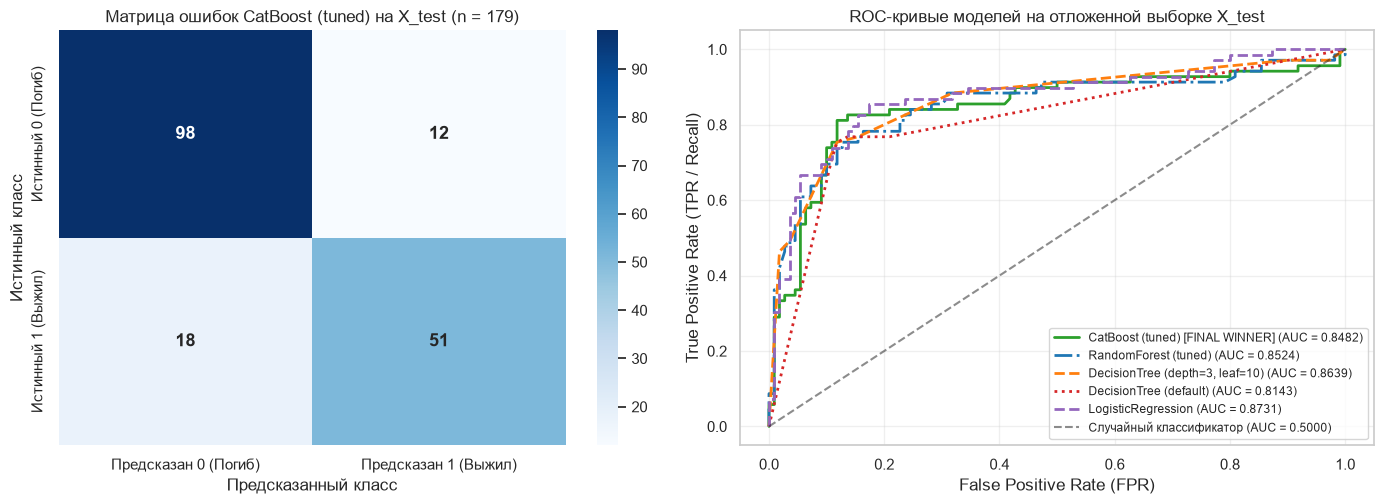

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# 1. Матрица ошибок для выбранной финальной модели CatBoost (tuned)
winner_model = final_candidates["CatBoost (tuned) [FINAL WINNER]"]
y_pred_win = winner_model.predict(X_test)
cm_win = confusion_matrix(y_test, y_pred_win)

sns.heatmap(
    cm_win,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Предсказан 0 (Погиб)", "Предсказан 1 (Выжил)"],
    yticklabels=["Истинный 0 (Погиб)", "Истинный 1 (Выжил)"],
    annot_kws={"size": 13, "weight": "bold"},
    ax=axes[0],
)
axes[0].set_title("Матрица ошибок CatBoost (tuned) на X_test (n = 179)")
axes[0].set_xlabel("Предсказанный класс")
axes[0].set_ylabel("Истинный класс")

# 2. ROC-кривые ключевых моделей на X_test
plot_models = [
    ("CatBoost (tuned) [FINAL WINNER]", "#2ca02c", "-"),
    ("RandomForest (tuned)", "#1f77b4", "-."),
    ("DecisionTree (depth=3, leaf=10)", "#ff7f0e", "--"),
    ("DecisionTree (default)", "#d62728", ":"),
    ("LogisticRegression", "#9467bd", "--"),
]
for mname, col, ls in plot_models:
    fpr, tpr, auc_val = roc_curves_data[mname]
    axes[1].plot(fpr, tpr, color=col, linestyle=ls, linewidth=2, label=f"{mname} (AUC = {auc_val:.4f})")

axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Случайный классификатор (AUC = 0.5000)")
axes[1].set_title("ROC-кривые моделей на отложенной выборке X_test")
axes[1].set_xlabel("False Positive Rate (FPR)")
axes[1].set_ylabel("True Positive Rate (TPR / Recall)")
axes[1].legend(loc="lower right", fontsize=8.8)

plt.tight_layout()
plt.show()


### 5.2. Важность признаков: встроенная (`feature_importances_`) против перестановочной (`Permutation Importance`)
Сравним два способа оценки вклада признаков для `CatBoost (tuned)` и `RandomForest (default)`:
1. **Встроенная важность (`Built-in Feature Importance`)**: суммарное снижение примеси (`Gini Importance` / `MDI` в `RandomForest`) или изменение предсказаний в листьях (`PredictionValuesChange` в `CatBoost`) по всем сплитам дерева после `OneHotEncoder`.
2. **Перестановочная важность (`Permutation Importance` на `X_test`)**: насколько падает метрика `F1` на отложенной выборке при случайном перемешивании значений каждого исходного признака (`30` повторений).


In [19]:
# 1. Встроенная важность после препроцессора (17 закодированных признаков)
cb_clf = winner_model.named_steps["clf"]
rf_def_model = final_candidates["RandomForest (default)"]
rf_clf = rf_def_model.named_steps["clf"]

encoded_feat_names = list(winner_model.named_steps["pre"].get_feature_names_out())
cb_builtin = cb_clf.feature_importances_ / cb_clf.feature_importances_.sum()
rf_builtin = rf_clf.feature_importances_ / rf_clf.feature_importances_.sum()

builtin_df = pd.DataFrame({
    "Признак (после OHE)": encoded_feat_names,
    "CatBoost (tuned) Built-in": np.round(cb_builtin, 4),
    "RandomForest (default) Gini Imp.": np.round(rf_builtin, 4),
}).sort_values("CatBoost (tuned) Built-in", ascending=False)

# 2. Перестановочная важность на исходных признаках X_test (по падению F1)
perm_cb = permutation_importance(
    winner_model, X_test, y_test, scoring="f1", n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1
)
perm_rf = permutation_importance(
    rf_def_model, X_test, y_test, scoring="f1", n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1
)

perm_df = pd.DataFrame({
    "Исходный признак": X_test.columns,
    "CatBoost Perm. Drop F1 (mean)": np.round(perm_cb.importances_mean, 4),
    "CatBoost Perm. Drop F1 (std)": np.round(perm_cb.importances_std, 4),
    "RandomForest Perm. Drop F1 (mean)": np.round(perm_rf.importances_mean, 4),
    "RandomForest Perm. Drop F1 (std)": np.round(perm_rf.importances_std, 4),
}).sort_values("CatBoost Perm. Drop F1 (mean)", ascending=False)

print("Топ-10 признаков по встроенной важности (Built-in / Gini Importance):")
display(builtin_df.head(10))

print("\nПерестановочная важность (Permutation Importance на X_test, падение F1 при перемешивании столбца):")
display(perm_df)


Топ-10 признаков по встроенной важности (Built-in / Gini Importance):


,Признак (после OHE),CatBoost (tuned) Built-in,RandomForest (default) Gini Imp.
4,Fare,0.2583,0.2340
1,Age,0.2022,0.2112
0,Pclass,0.1097,0.0744
14,Title_Mr,0.0945,0.0949
8,Sex_male,0.0894,0.1010
5,FamilySize,0.0500,0.0513
7,Sex_female,0.0397,0.0730
11,Embarked_S,0.0335,0.0136
2,SibSp,0.0270,0.0286
13,Title_Miss,0.0201,0.0271



Перестановочная важность (Permutation Importance на X_test, падение F1 при перемешивании столбца):


,Исходный признак,CatBoost Perm. Drop F1 (mean),CatBoost Perm. Drop F1 (std),RandomForest Perm. Drop F1 (mean),RandomForest Perm. Drop F1 (std)
9,Title,0.1468,0.0299,0.0962,0.0251
1,Sex,0.1443,0.0304,0.2099,0.0389
0,Pclass,0.0733,0.0272,0.0640,0.0201
5,Fare,0.0704,0.0204,0.0587,0.0260
2,Age,0.0662,0.0244,0.0572,0.0232
6,Embarked,0.0180,0.0124,0.0077,0.0139
7,FamilySize,0.0032,0.0092,0.0096,0.0078
4,Parch,-0.0015,0.0093,0.0120,0.0082
8,IsAlone,-0.0065,0.0042,0.0026,0.0057
3,SibSp,-0.0181,0.0103,-0.0021,0.0089


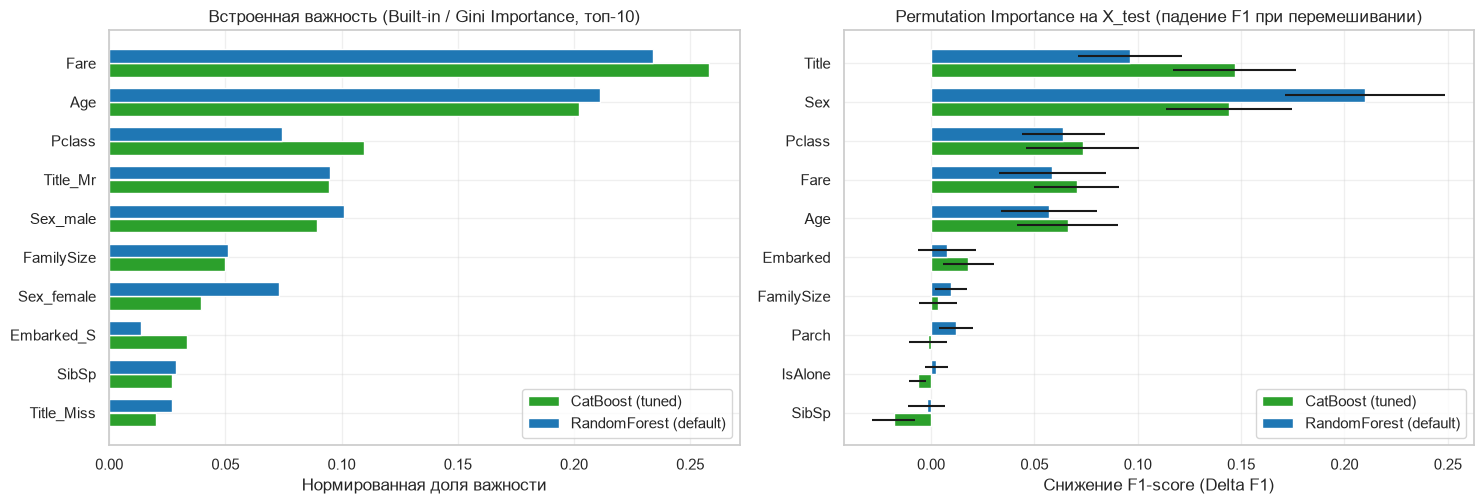

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

# График 1: Встроенная важность (Топ-10 признаков после OneHotEncoder)
top_b = builtin_df.head(10).iloc[::-1]
y_pos = np.arange(len(top_b))
axes[0].barh(y_pos - 0.18, top_b["CatBoost (tuned) Built-in"], height=0.35, color="#2ca02c", label="CatBoost (tuned)")
axes[0].barh(y_pos + 0.18, top_b["RandomForest (default) Gini Imp."], height=0.35, color="#1f77b4", label="RandomForest (default)")
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(top_b["Признак (после OHE)"])
axes[0].set_title("Встроенная важность (Built-in / Gini Importance, топ-10)")
axes[0].set_xlabel("Нормированная доля важности")
axes[0].legend(loc="lower right")

# График 2: Permutation Importance на X_test
top_p = perm_df.iloc[::-1]
y_pos_p = np.arange(len(top_p))
axes[1].barh(
    y_pos_p - 0.18,
    top_p["CatBoost Perm. Drop F1 (mean)"],
    xerr=top_p["CatBoost Perm. Drop F1 (std)"],
    height=0.35,
    color="#2ca02c",
    label="CatBoost (tuned)",
)
axes[1].barh(
    y_pos_p + 0.18,
    top_p["RandomForest Perm. Drop F1 (mean)"],
    xerr=top_p["RandomForest Perm. Drop F1 (std)"],
    height=0.35,
    color="#1f77b4",
    label="RandomForest (default)",
)
axes[1].set_yticks(y_pos_p)
axes[1].set_yticklabels(top_p["Исходный признак"])
axes[1].set_title("Permutation Importance на X_test (падение F1 при перемешивании)")
axes[1].set_xlabel("Снижение F1-score (Delta F1)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


### Почему `Permutation Importance` честнее `Gini Importance` для непрерывных признаков `Fare` и `Age`
Сравнение двух графиков выше демонстрирует классическое смещение встроенной важности деревьев (`Impurity-based Importance Bias`):
1. **Искажение во встроенной важности (`feature_importances_`)**: и в `CatBoost (tuned)`, и в `RandomForest (default)` первые два места занимают непрерывные признаки высокой кардинальности — `Fare` (`25.83%` в CatBoost, `23.40%` в RF) и `Age` (`20.22%` в CatBoost, `21.12%` в RF). Причина в том, что у `Fare` более `220` уникальных значений, а у `Age` — более `80`: на нижних уровнях каждого дерева алгоритм находит десятки порогов дробления именно по этим непрерывным переменным (в том числе подгоняясь под локальный шум), суммируя их вклад. Одновременно мощные категориальные предикторы `Title` и `Sex` после `OneHotEncoder` разбиваются на несколько коллинеарных бинарных столбцов (`Title_Mr`, `Title_Mrs`, `Title_Miss`, `Sex_male`, `Sex_female`), которые «растаскивают» важность между собой.
2. **Честная оценка через `Permutation Importance` на отложенной выборке**: когда мы перемешиваем значения признака на независимом `X_test` и замеряем реальную потерю качества `F1`, картина меняется на физически достоверную:
   - В `CatBoost (tuned)` лидируют **`Title`** ($\Delta F1 = -0.1468 \pm 0.0299$) и **`Sex`** ($\Delta F1 = -0.1443 \pm 0.0304$), далее идут **`Pclass`** ($-0.0733 \pm 0.0272$), **`Fare`** ($-0.0704 \pm 0.0204$) и **`Age`** ($-0.0662 \pm 0.0244$).
   - В `RandomForest (default)` перемешивание `Sex` обрушивает `F1` на **$-0.2099 \pm 0.0389$**, `Title` — на **$-0.0962 \pm 0.0251$**, `Pclass` — на **$-0.0640 \pm 0.0201$**, тогда как перемешивание `Fare` ($-0.0587$) и `Age` ($-0.0572$) даёт в 3.5 раза меньший эффект, чем `Sex`.

---

## 6. Итоговые выводы по работе

1. **Математика разбиения узлов и роль конструирования признаков (`Title`)**:
   - Ручной расчёт критерия Джини и энтропии Шеннона на `X_train` (`n = 712`, `Gini(root) = 0.4728`, `Entropy(root) = 0.9604`), полностью подтверждённый `assert np.isclose(...)` против `DecisionTreeClassifier(max_depth=1)`, показал, что сплит по сконструированному признаку `Title == 'Mr'` даёт больший прирост информации (`IG_Gini = 0.1459`, `IG_Entropy = 0.2320`), чем сплит по `Sex == 'female'` (`IG_Gini = 0.1426`, `IG_Entropy = 0.2227`). Выделение мальчиков (`Master`) из общей группы мужчин позволяет уже в корне получить чистый узел взрослых мужчин (`n = 412`, `Gini = 0.2591`).

2. **Механизм переобучения одиночного дерева решений**:
   - Неограниченное дерево `DecisionTreeClassifier(default)` достигает глубины `18` и дробит `712` объектов на `164` листа, показывая почти безошибочное запоминание трейна (`Train F1 = 0.9786`, `Train Accuracy = 0.9860`) при резкой деградации на кросс-валидации (`CV F1 = 0.7209 +- 0.0133`, `CV ROC-AUC = 0.7752 +- 0.0111`).
   - Введение структурной регуляризации (`max_depth = 3, min_samples_leaf = 10`, всего `8` листьев) сокращает разрыв `Train - CV F1` с `0.2577` до `0.0074`, поднимает `CV F1` до `0.7623 +- 0.0550`, а `CV ROC-AUC` — на `+0.0838` (до `0.8590 +- 0.0364`).

3. **Почему лидер одного фолда не обязан быть лучшей моделью в целом**:
   - Анализ 5 фолдов `StratifiedKFold` показал, что на каждом фолде выигрывает разный алгоритм: на `Fold 1` — `LightGBM` (`F1 = 0.7925`), на `Fold 2` — `CatBoost` (`0.7500`), на `Fold 3` — одиночное дерево `DecisionTree (depth=3, leaf=10)` (`0.8491`), на `Fold 4` — `RandomForest` (`0.7636`), на `Fold 5` — `LogisticRegression` (`0.7961`).
   - Одиночное дерево, поставившее рекорд `0.8491` на `Fold 3`, имеет максимальную дисперсию (`std = 0.0550`) и на `Fold 2` падает до `0.6809`. Оценка по одному разбиению или одному фолду ведёт к выбору нестабильной модели, случайно попавшей в структуру конкретной подвыборки.

4. **Сравнение Bagging (`RandomForest`) и Gradient Boosting (`XGBoost`, `LightGBM`, `CatBoost`)**:
   - Базовый `RandomForest (default)` за счёт усреднения `200` деревьев радикально улучшает ранжирование относительно одного дерева (`CV ROC-AUC = 0.8688 +- 0.0163` против `0.7752`), но без ограничения глубины всё ещё переобучается (`Train F1 = 0.9788` против `CV F1 = 0.7389`).
   - Модели градиентного бустинга (`XGBoost`, `LightGBM`, `CatBoost`), строящие композицию неглубоких деревьев (`depth = 4`), лидируют по площади под ROC-кривой уже из коробки (`CV ROC-AUC`: `CatBoost = 0.8943`, `XGBoost = 0.8877`, `LightGBM = 0.8826`).

5. **Эффект подбора гиперпараметров (`GridSearchCV` / `RandomizedSearchCV`)**:
   - Для `RandomForest` ограничение `max_depth = 4` через `GridSearchCV` убрало переобучение (`Train F1 = 0.7791`, `CV F1 = 0.7697 +- 0.0406`, прирост `+0.0308` к `CV F1`).
   - Для `LightGBM` ограничение числа листьев `num_leaves = 7` и `min_child_samples = 20` повысило `CV F1` с `0.7585` до `0.7782 +- 0.0214`.
   - Для `CatBoost` настройка `depth = 5, iterations = 400, learning_rate = 0.05, l2_leaf_reg = 3` дала наилучший результат по кросс-валидации: **`CV F1 = 0.7785 +- 0.0164`**, **`CV ROC-AUC = 0.8904 +- 0.0182`**, **`CV Accuracy = 0.8385 +- 0.0148`** при минимальном разбросе между фолдами (`std = 0.0164`).

6. **Проверка на отложенной тестовой выборке `X_test` (`n = 179`)**:
   - Выбранный строго по `CV` победитель `CatBoost (tuned)` подтвердил высокое качество на ранее не виденных данных: **`Test Accuracy = 0.8324`**, **`Test Precision = 0.8095`** (лучшая точность положительного прогноза среди всех моделей), **`Test Recall = 0.7391`**, **`Test F1 = 0.7727`**, **`Test ROC-AUC = 0.8482`** (`TN = 98, FP = 12, FN = 18, TP = 51`), превзойдя базовый `CatBoost (default)` на **`+0.0399` по `Test F1`** (`0.7727` против `0.7328`).
   - На компактном табличном датасете (`n < 1000`) с грамотно сконструированными признаками (`Title`, `FamilySize`, `IsAlone`) хорошо регуляризованные простые модели (`LogisticRegression`: `Test ROC-AUC = 0.8731`, `DecisionTree (depth=3, leaf=10)`: `Test F1 = 0.7761`, `Test ROC-AUC = 0.8639`) выступают вплотную к сложным ансамблям, что подчёркивает первичность качества признаков и контроля ёмкости модели.

7. **Интерпретируемость и честная оценка важности признаков**:
   - Встроенная важность (`Gini Importance` / `PredictionValuesChange`) завышает вклад непрерывных переменных `Fare` (`25.8%`) и `Age` (`20.2%`) из-за большого числа точек ветвления на нижних уровнях деревьев.
   - Перестановочная важность (`Permutation Importance` на `X_test`) устраняет это смещение и выстраивает содержательно верную иерархию факторов выживания на «Титанике»: **`Title`** ($\Delta F1 = -0.1468$) и **`Sex`** ($-0.1443$) на первом месте («женщины и дети первыми»), затем социально-экономический статус **`Pclass`** ($-0.0733$) и **`Fare`** ($-0.0704$), и далее возраст **`Age`** ($-0.0662$).
